<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-04/lab-014b-transfer-jax.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 014b
<hr/>

# Lab 014b — Transfer learning in JAX

A network trained on a large data set has learned features that are often useful for a different task with far fewer labels. This notebook turns that observation into a recipe for one's own research data: take a trained network, freeze its feature extractor, add new layers, train them, and optionally fine-tune the whole network with a smaller learning rate; or take a network pretrained by others and adapt it in the same way. Lab 014a does the same in PyTorch; the two notebooks have identical sections. This one uses JAX (array computing with automatic differentiation and compilation by XLA, Accelerated Linear Algebra), the neural-network library Flax in its `flax.nnx` interface, and the optimisers of Optax.

The target task is BloodMNIST, microscope images of single blood cells of eight types. Two source networks are reused: the convolutional neural network (CNN) trained on CIFAR-10 photographs in Lab 013b, and a residual network with 18 layers (ResNet-18) trained on ImageNet; Section 4 applies the same network to EuroSAT, small satellite images of European landscapes, a target much closer to its source. Flax has no collection of pretrained image networks comparable to `torchvision.models`, so we write ResNet-18 in `flax.nnx` and convert the published PyTorch weights into it.

1. Transfer learning in one formula.
2. A CIFAR-10 network on blood cells.
3. A pretrained ResNet-18.
4. A pretrained ResNet-18 on satellite images.
5. Cheat sheet for PyTorch and JAX.

Everything runs on the central processing unit (CPU); the whole notebook takes about 250 (measured on 8 cores of a shared machine; the JAX training loops on the CPU are several times slower than their PyTorch counterparts) minutes.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run the cells in order with **Shift + Enter**: later cells use variables defined earlier.
> 3. `numpy`, `matplotlib`, `jax`, `flax`, `optax`, `scikit-learn`, `torch` and `torchvision` are pre-installed in Colab (PyTorch is used only to download the pretrained ResNet-18 weights and to check their conversion). If `flax.nnx` is missing (old Flax), run `!pip install -U flax optax` and restart the session.
> 4. BloodMNIST is read from `data/` and downloaded from Zenodo if missing (35 MB for $28\times28$ pixels, 156 MB for $64\times64$). CIFAR-10 is looked for in `~/.keras/datasets/cifar-10-batches-py` and `data/`, otherwise downloaded (163 MB). The ResNet-18 weights (45 MB) are downloaded by `torchvision` on first use.
> 5. The CIFAR-10 network is loaded from `results/Lab_013b_regularised_cnn.msgpack`, written by Lab 013b. Without that file it is retrained briefly, and the numbers of Section 2 change.
> 6. Trained weights are written to `results/`.

The first cell tells JAX to use the CPU and hides every graphics card; this must happen before `jax` and `torch` are imported. PyTorch, used only for the pretrained weights, is limited to 8 threads.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # JAX: CPU backend only
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # no graphics card visible to any framework

import time, gzip, pickle, tarfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import optax
import flax
from flax import nnx
import flax.serialization
import torch, torchvision                    # only to download and check the pretrained ResNet-18 weights
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

torch.set_num_threads(min(8, os.cpu_count()))

UJBlue, UJNavy, DSOrange, UJGray, Green = "#005CA7", "#002B5C", "#D35A05", "#5A6270", "#2E8B57"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 15, "axes.titlesize": 16,
                     "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})

DATA, RESULTS = "data", "results"
for d in (DATA, RESULTS): os.makedirs(d, exist_ok=True)
T_START = time.time()
print("JAX", jax.__version__, "| Flax", flax.__version__, "| Optax", optax.__version__, "| devices:", jax.devices(),
      "| torchvision", torchvision.__version__)

JAX 0.11.0 | Flax 0.12.8 | Optax 0.2.6 | devices: [CpuDevice(id=0)] | torchvision 0.24.0+cpu


## 1. Transfer learning in one formula

Every classifier of the previous labs can be cut into two parts. The body $f_\varphi$, with parameters $\varphi$, turns an image $x$ into a feature vector $h$ of length $d$; in a CNN these are the convolutional layers. The head $g_\psi$, with parameters $\psi$, turns the features into $K$ class scores $z$, usually with one or two dense layers:
$$h=f_\varphi(x)\in\mathbb{R}^d,\qquad z=g_\psi(h)=g_\psi\big(f_\varphi(x)\big)\in\mathbb{R}^K. \tag{1}$$
Training on a source task (CIFAR-10, ImageNet) gives parameters $\varphi_s$ and $\psi_s$. The source head predicts the source classes and is discarded. For the target task, with its own $K$ classes and $N$ labelled examples $(x_i,y_i)$, a new head with random initial $\psi$ is attached, and there are two ways of training it, both minimising the mean cross-entropy $L$ over the labelled examples.

In freezing, the body keeps the source parameters $\varphi_s$ and only the head is trained,
$$\psi^\ast=\arg\min_\psi\ \frac1N\sum_{i=1}^N L\Big(g_\psi\big(f_{\varphi_s}(x_i)\big),\,y_i\Big). \tag{2}$$
In fine-tuning, training continues from $\varphi_s$ and $\psi^\ast$ with both sets of parameters free, but with a learning rate for the body about ten times smaller than the rate $\eta$ used for the head; written for plain gradient descent on the loss $\mathcal{L}$ of equation (2) (Adam uses the same two rates),
$$\varphi\leftarrow\varphi-\eta_\varphi\,\nabla_\varphi\mathcal{L},\qquad \psi\leftarrow\psi-\eta\,\nabla_\psi\mathcal{L},\qquad \eta_\varphi=\frac{\eta}{10}. \tag{3}$$
The small rate lets the body move away from $\varphi_s$ only as far as the target data require; a large rate in the first steps, while the head is still random, would send large and meaningless gradients into the pretrained body.

With a frozen body, the features of equation (1) do not change during training. They can be computed once for every labelled image and stored, and training the head becomes a small problem on a table with $N$ rows and $d$ columns; with a linear head it is multinomial logistic regression. This is the fastest form of transfer learning and the first one to try on new data. The sketch shows the two parts of the network.

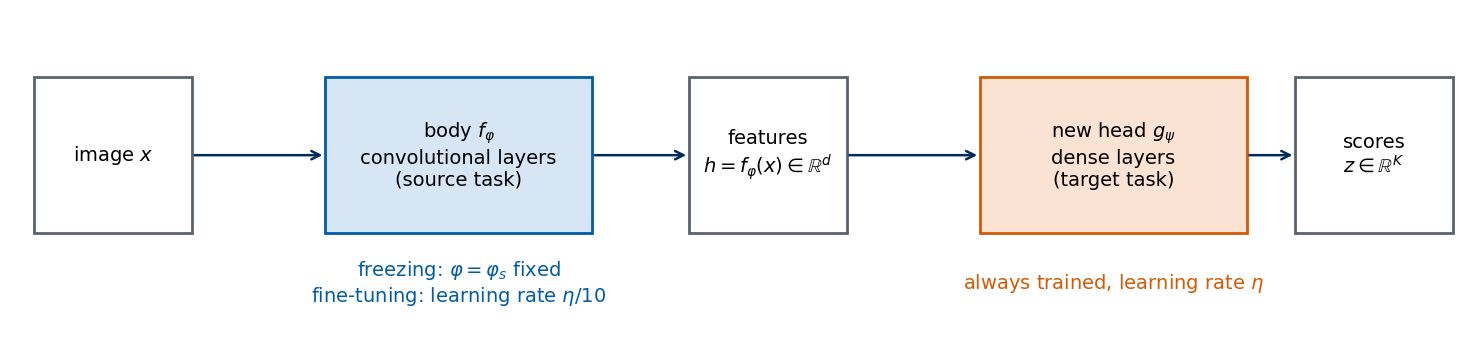

In [2]:
fig, ax = plt.subplots(figsize=(15, 3.8)); ax.set_xlim(0, 12); ax.set_ylim(0, 3); ax.axis("off")
boxes = [(0.2, "image $x$", "white", UJGray), (2.6, "body $f_\\varphi$\nconvolutional layers\n(source task)", "#D6E6F5", UJBlue),
         (5.6, "features\n$h=f_\\varphi(x)\\in\\mathbb{R}^d$", "white", UJGray),
         (8.0, "new head $g_\\psi$\ndense layers\n(target task)", "#FBE3D3", DSOrange), (10.6, "scores\n$z\\in\\mathbb{R}^K$", "white", UJGray)]
for x0, txt, fc, ec in boxes:
    w = 2.2 if "body" in txt or "head" in txt else 1.3
    ax.add_patch(plt.Rectangle((x0, 1.0), w, 1.4, fc=fc, ec=ec, lw=2))
    ax.text(x0 + w / 2, 1.7, txt, ha="center", va="center", fontsize=14)
for x0, x1 in [(1.5, 2.6), (4.8, 5.6), (6.9, 8.0), (10.2, 10.6)]:
    ax.annotate("", xy=(x1, 1.7), xytext=(x0, 1.7), arrowprops=dict(arrowstyle="->", lw=1.8, color=UJNavy))
ax.text(3.7, 0.55, "freezing: $\\varphi=\\varphi_s$ fixed\nfine-tuning: learning rate $\\eta/10$", ha="center", va="center", fontsize=14, color=UJBlue)
ax.text(9.1, 0.55, "always trained, learning rate $\\eta$", ha="center", va="center", fontsize=14, color=DSOrange)
plt.tight_layout(); plt.show()

Transfer learning helps when three conditions meet: the labelled target set is small compared with the number of parameters of the body, the source images share low-level statistics with the target images (edges, textures, colour contrasts), and the target task is hard enough that a small network trained from random initialisation on the few labels does not already solve it. When one of them fails, transfer can bring nothing. Section 10 of Lab 013 gave such a case. The body of the regularised CIFAR-10 CNN, frozen, with a new head trained on MNIST digits, reached 86.8%, 95.2% and 96.3% test accuracy with 10, 100 and 1000 digits per class, while the same network trained from random initialisation reached 88.1%, 95.3% and 96.7% (Lab 013b, JAX); the PyTorch version, Lab 013a, gave 87.0%, 95.8%, 96.2% against 89.3%, 96.5%, 97.2%. MNIST is easy enough that 100 digits per class suffice for a small CNN, and white strokes on black share little with the colour photographs of CIFAR-10.

Blood cells are a harder target: eight classes that differ in the shape and texture of the nucleus and in the colour of granules in the cytoplasm, with labels that require an expert. Section 2 reuses the CIFAR-10 network of Lab 013 on them; Section 3 does the same with a large network pretrained on ImageNet.

### CIFAR-10 and MNIST

Both data sets of that counterexample return in this lab: CIFAR-10 as the source of our own pretrained network, MNIST only as the target on which transfer failed.

CIFAR-10 (A. Krizhevsky, *Learning Multiple Layers of Features from Tiny Images*, technical report, University of Toronto, 2009, [data and report](https://www.cs.toronto.edu/~kriz/cifar.html)) consists of 60 000 colour photographs of $32\times32$ pixels with three channels (red, green, blue, each an integer from 0 to 255), 50 000 for training and 10 000 for testing, 6000 per class. The ten classes are everyday objects and animals: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The page states no licence; the authors ask users to cite the report.

MNIST (Y. LeCun, L. Bottou, Y. Bengio, P. Haffner, *Gradient-based learning applied to document recognition*, Proceedings of the IEEE 86, 2278 (1998), [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)) consists of 70 000 greyscale images of handwritten digits $0,\dots,9$, $28\times28$ pixels with one channel (0 = black background, 255 = white stroke), 60 000 for training and 10 000 for testing.

Both are read from the local caches used in Lab 013 or downloaded from the original sources.

In [3]:
CIFAR_URL = "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
CIFAR_CANDIDATES = [os.path.expanduser("~/.keras/datasets/cifar-10-batches-py"), os.path.join(DATA, "cifar-10-batches-py")]

def cifar_dir():
    # local copy of the CIFAR-10 batches, downloaded from the authors' page if missing (163 MB)
    for d in CIFAR_CANDIDATES:
        if os.path.exists(os.path.join(d, "test_batch")): return d
    tgz = os.path.join(DATA, "cifar-10-python.tar.gz")
    print("downloading CIFAR-10 (163 MB) ...")
    urllib.request.urlretrieve(CIFAR_URL, tgz)
    with tarfile.open(tgz) as t: t.extractall(DATA, filter="data")
    return os.path.join(DATA, "cifar-10-batches-py")

def load_batch(d, name):
    with open(os.path.join(d, name), "rb") as f:
        b = pickle.load(f, encoding="bytes")
    return b[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), np.array(b[b"labels"], dtype=np.int32)  # (N, 32, 32, 3)

D_CIFAR = cifar_dir()
Xc_tr_raw = np.concatenate([load_batch(D_CIFAR, f"data_batch_{i}")[0] for i in range(1, 6)])
yc_tr = np.concatenate([load_batch(D_CIFAR, f"data_batch_{i}")[1] for i in range(1, 6)])
Xc_te_raw, yc_te = load_batch(D_CIFAR, "test_batch")
with open(os.path.join(D_CIFAR, "batches.meta"), "rb") as f:
    CIFAR_CLASSES = [c.decode() for c in pickle.load(f, encoding="bytes")[b"label_names"]]
CIFAR_MEAN = (Xc_tr_raw / 255.0).mean(axis=(0, 1, 2)).astype(np.float32)   # (3,) as in Lab 013a
CIFAR_STD = (Xc_tr_raw / 255.0).std(axis=(0, 1, 2)).astype(np.float32)     # (3,)

def cifar_array(X_raw):
    # uint8 (N, 32, 32, 3) -> standardised float32 (N, 32, 32, 3), channels last
    return ((X_raw.astype(np.float32) / 255 - CIFAR_MEAN) / CIFAR_STD).astype(np.float32)

Xc_te = cifar_array(Xc_te_raw)
print("CIFAR-10 training:", Xc_tr_raw.shape, Xc_tr_raw.dtype, "| test:", Xc_te_raw.shape, "| classes:", CIFAR_CLASSES)
print("CIFAR-10 test:", tuple(Xc_te.shape), "| channel means", CIFAR_MEAN.round(3), "| standard deviations", CIFAR_STD.round(3))

CIFAR-10 training: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3) | classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
CIFAR-10 test: (10000, 32, 32, 3) | channel means [0.491 0.482 0.447] | standard deviations [0.247 0.243 0.262]


In [4]:
MNIST_RAW, LOCAL_MNIST = os.path.join(DATA, "MNIST_raw"), os.path.expanduser("~/.pytorch/MNIST_data/MNIST/raw")
MNIST_MIRRORS = ["https://ossci-datasets.s3.amazonaws.com/mnist/", "https://storage.googleapis.com/cvdf-datasets/mnist/"]

def mnist_idx(name):
    # one MNIST file in the IDX format: images -> (n, 28, 28) uint8, labels -> (n,) uint8
    for d in (MNIST_RAW, LOCAL_MNIST):
        p = os.path.join(d, name)
        if os.path.exists(p): raw = open(p, "rb").read(); break
        if os.path.exists(p + ".gz"): raw = gzip.open(p + ".gz").read(); break
    else:
        os.makedirs(MNIST_RAW, exist_ok=True)
        for m in MNIST_MIRRORS:
            try:
                urllib.request.urlretrieve(m + name + ".gz", os.path.join(MNIST_RAW, name + ".gz")); break
            except Exception: pass
        raw = gzip.open(os.path.join(MNIST_RAW, name + ".gz")).read()
    if raw[3] == 3:
        n, r, c = np.frombuffer(raw[4:16], ">i4")
        return np.frombuffer(raw[16:], np.uint8).reshape(n, r, c)
    return np.frombuffer(raw[8:], np.uint8)

Xm_te, ym_te = mnist_idx("t10k-images-idx3-ubyte"), mnist_idx("t10k-labels-idx1-ubyte")     # test images suffice for the figure
assert Xm_te.shape == (10000, 28, 28)
print("MNIST test images:", Xm_te.shape, Xm_te.dtype, "| digits per class:", np.bincount(ym_te))

MNIST test images: (10000, 28, 28) uint8 | digits per class: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


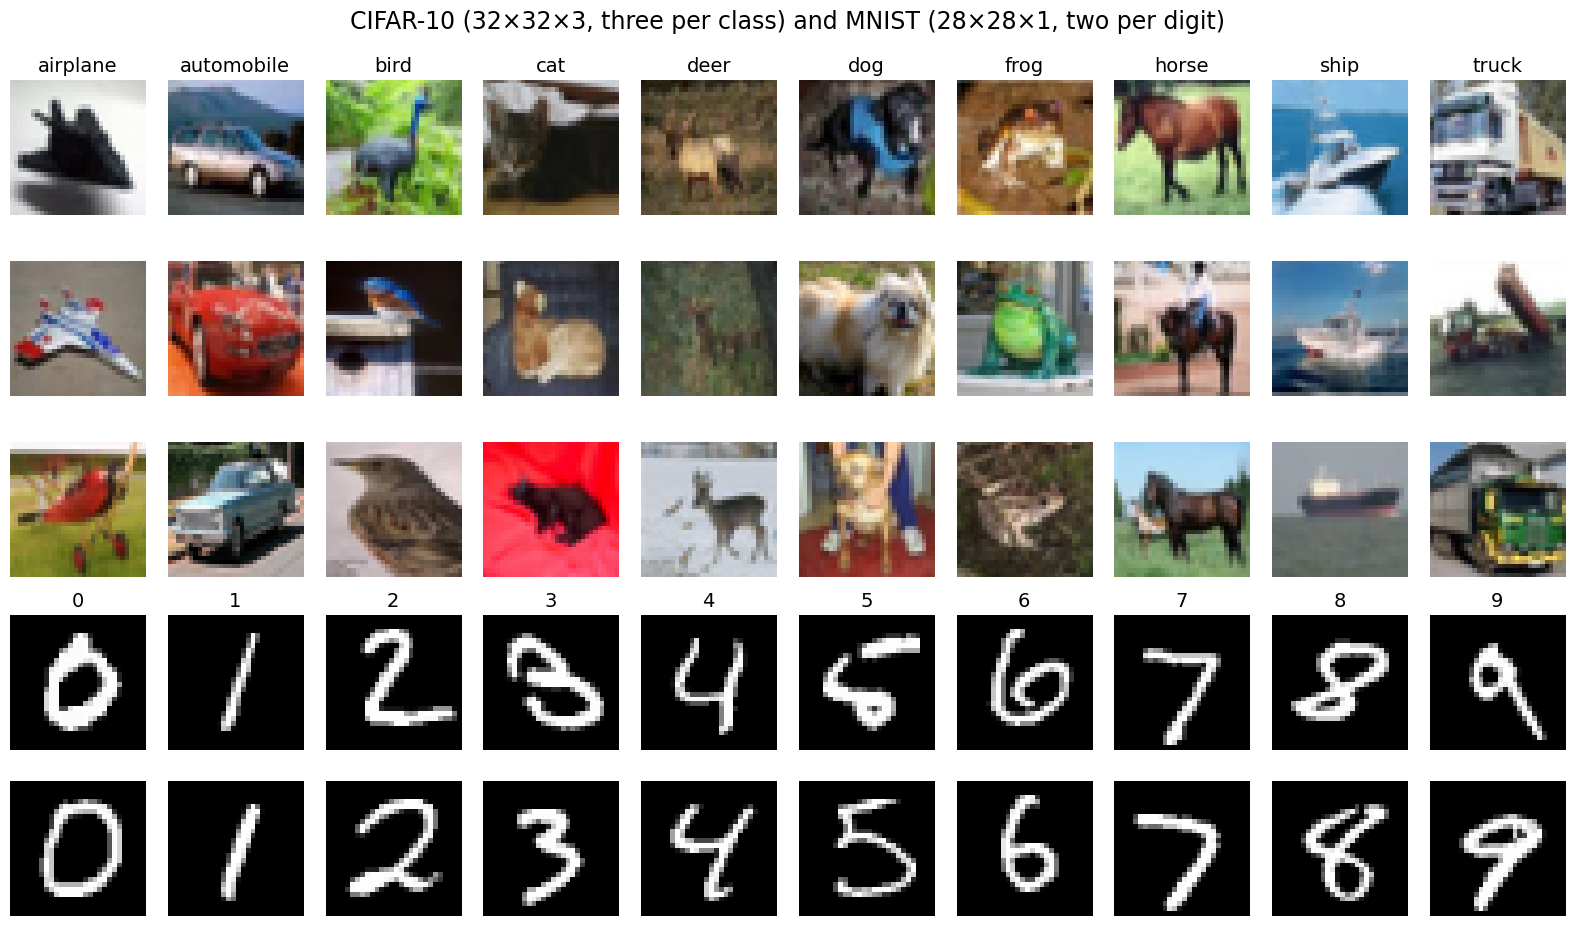

In [5]:
fig, axes = plt.subplots(5, 10, figsize=(16, 9.5), gridspec_kw={"height_ratios": [1, 1, 1, 0.9, 0.9]})
for c in range(10):
    for r in range(3):
        axes[r, c].imshow(Xc_tr_raw[np.flatnonzero(yc_tr == c)[r]])
    axes[0, c].set_title(CIFAR_CLASSES[c], fontsize=14)
    for r in range(2):
        axes[3 + r, c].imshow(Xm_te[np.flatnonzero(ym_te == c)[r]], cmap="gray")
    axes[3, c].set_title(str(c), fontsize=14)
for a in axes.ravel(): a.axis("off")
fig.suptitle("CIFAR-10 (32×32×3, three per class) and MNIST (28×28×1, two per digit)"); plt.tight_layout(); plt.show()

## 2. A CIFAR-10 network on blood cells

The first source network is our own: the regularised CNN that Lab 013 trained on CIFAR-10 photographs. We put its convolutional body in front of new layers for the eight cell types and compare three ways of training with 10, 100 and 800 labelled cells per type.

### Blood cell images

The images come from A. Acevedo, A. Merino, S. Alférez, Á. Molina, L. Boldú, J. Rodellar, *A dataset of microscopic peripheral blood cell images for development of automatic recognition systems*, Data in Brief 30, 105474 (2020), [doi:10.1016/j.dib.2020.105474](https://doi.org/10.1016/j.dib.2020.105474): 17 092 images of individual normal cells in peripheral blood smears, recorded with a CellaVision DM96 analyser at the Hospital Clínic of Barcelona from donors without infection, haematological or oncological disease and without pharmacological treatment, and labelled by clinical pathologists. The originals have $360\times363$ pixels. BloodMNIST is the version of the MedMNIST collection (J. Yang et al., *MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical image classification*, Scientific Data 10, 41 (2023), [doi:10.1038/s41597-022-01721-8](https://doi.org/10.1038/s41597-022-01721-8)), resized to $28\times28$ and $64\times64$ pixels with three channels (red, green, blue, integers 0–255) and split into 11 959 training, 1712 validation and 3421 test images; it is distributed on [Zenodo](https://zenodo.org/records/10519652) under the Creative Commons Attribution 4.0 licence. We draw the labelled examples from the training images and report every accuracy on the full test set; the validation images are not used.

The eight classes, with their integer labels:

| $c$ | cell type | what it is |
|---|---|---|
| 0 | basophil | granulocyte with large dark-violet granules that often hide the nucleus; the rarest white blood cell |
| 1 | eosinophil | granulocyte with large orange-red granules and a nucleus of usually two lobes; active against parasites and in allergy |
| 2 | erythroblast | nucleated precursor of the red blood cell, normally found in the bone marrow |
| 3 | immature granulocyte | precursors of the granulocytes: promyelocytes, myelocytes and metamyelocytes, grouped into one class |
| 4 | lymphocyte | small cell whose round, dense nucleus fills most of it, with a thin rim of blue cytoplasm; adaptive immunity |
| 5 | monocyte | the largest white blood cell, with a folded or kidney-shaped nucleus and grey-blue cytoplasm; precursor of macrophages |
| 6 | neutrophil | the most frequent white blood cell, with a nucleus of two to five lobes and pale, finely granular cytoplasm; first defence against bacteria |
| 7 | platelet | small fragment of a megakaryocyte without nucleus, involved in blood clotting |

Each `.npz` file holds `train_images` of shape $(N,H,W,3)$ with `uint8` values, `train_labels` of shape $(N,1)$, and the same arrays for `val` and `test`. The two resolutions contain the same cells in the same order. Section 2 uses the $28\times28$ version, Section 3 the $64\times64$ version.

In [6]:
BLOOD_URL = "https://zenodo.org/records/10519652/files/{}?download=1"
BLOOD_TYPES = ["basophil", "eosinophil", "erythroblast", "immature granulocyte",
               "lymphocyte", "monocyte", "neutrophil", "platelet"]

def load_blood(name):
    # read a MedMNIST .npz file from data/, download it from Zenodo if it is not there
    path = os.path.join(DATA, name)
    if not os.path.exists(path):
        print("downloading", name, "...")
        urllib.request.urlretrieve(BLOOD_URL.format(name), path)
    with np.load(path) as d:
        return {k: d[k] for k in d.files}

b28 = load_blood("bloodmnist.npz")
Xb_tr_raw, yb_tr = b28["train_images"], b28["train_labels"].ravel().astype(np.int32)   # (11959, 28, 28, 3) uint8
Xb_te_raw, yb_te = b28["test_images"], b28["test_labels"].ravel().astype(np.int32)     # (3421, 28, 28, 3)
b64 = load_blood("bloodmnist_64.npz")                                                   # the same cells at 64 x 64 pixels
assert Xb_tr_raw.shape == (11959, 28, 28, 3) and Xb_te_raw.shape == (3421, 28, 28, 3)
assert np.array_equal(b64["train_labels"].ravel(), yb_tr) and np.array_equal(b64["test_labels"].ravel(), yb_te)
BLOOD_GRID_PATH = None                                                                     # Lab 014a saves the grid for the slides
print(f"{'cell type':22s} {'training':>8s} {'test':>6s}")
for c, name in enumerate(BLOOD_TYPES):
    print(f"{name:22s} {np.sum(yb_tr == c):8d} {np.sum(yb_te == c):6d}")

cell type              training   test
basophil                    852    244
eosinophil                 2181    624
erythroblast               1085    311
immature granulocyte       2026    579
lymphocyte                  849    243
monocyte                    993    284
neutrophil                 2330    666
platelet                   1643    470


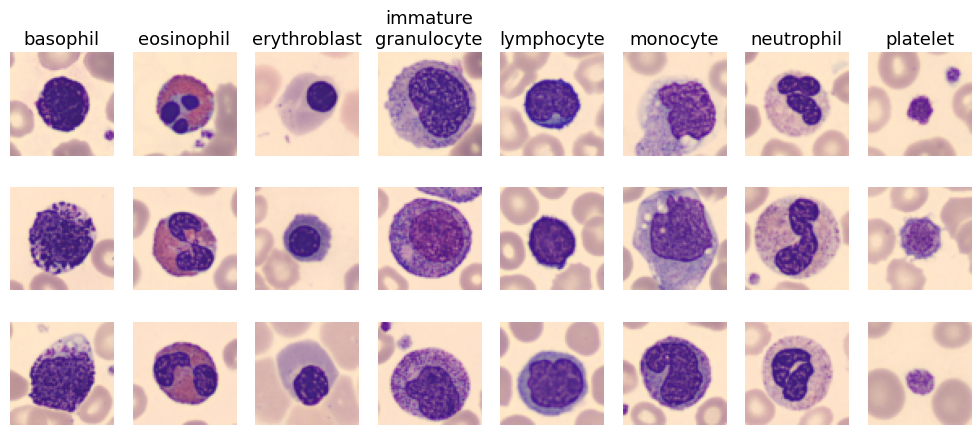

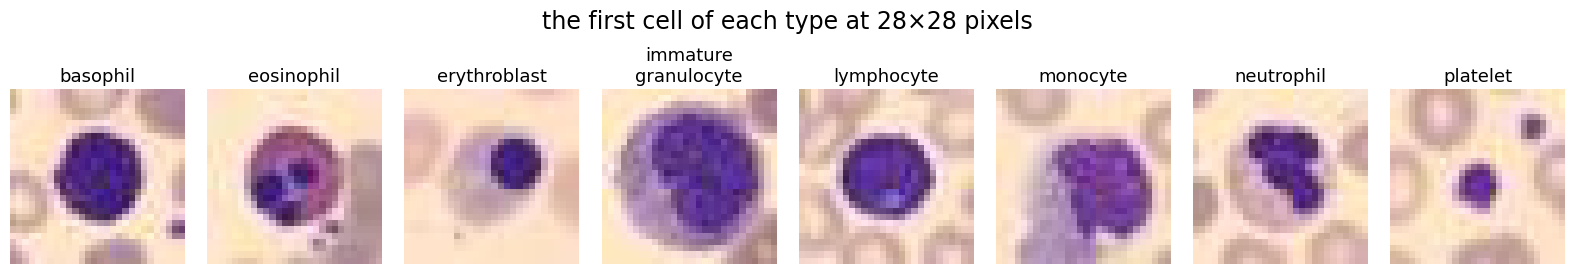

In [7]:
def blood_grid(path=None):
    # three training images per cell type at 64 x 64 pixels, large labels (also used on a slide)
    with plt.rc_context({"font.size": 13}):
        fig, axes = plt.subplots(3, 8, figsize=(10, 4.8))
        for c in range(8):
            for r in range(3):
                i = np.flatnonzero(yb_tr == c)[r]
                axes[r, c].imshow(b64["train_images"][i]); axes[r, c].axis("off")
            axes[0, c].set_title(BLOOD_TYPES[c].replace(" ", "\n"), fontsize=13)
        fig.tight_layout()
        if path: fig.savefig(path, dpi=150); print("saved", path)
        plt.show()

blood_grid(BLOOD_GRID_PATH)
fig, axes = plt.subplots(1, 8, figsize=(16, 3.0))
for c in range(8):
    axes[c].imshow(Xb_tr_raw[np.flatnonzero(yb_tr == c)[0]]); axes[c].axis("off"); axes[c].set_title(BLOOD_TYPES[c].replace(" ", "\n"), fontsize=13)
fig.suptitle("the first cell of each type at 28×28 pixels"); plt.tight_layout(); plt.show()

The classes are unbalanced: neutrophils are the most frequent type, lymphocytes the rarest with 849 training images. A balanced subset with 1000 cells per type therefore does not exist, and the largest budget we use is 800 cells per type (6400 images); the others are 10 and 100 per type. For each type we fix one random order of its training images (seed 0) and take the first 10, 100 or 800; the subsets are therefore nested, every cell of the 10-per-type subset is also in the larger ones. `SUB[n]` holds the indices of the selected images in the training set, `POS[n]` their positions inside the largest subset, so that arrays prepared once for the largest subset serve all budgets.

In [8]:
BUDGETS = [10, 100, 800]                       # labelled cells per type

def nested_subsets(y, budgets, seed=0):
    # one random order of the images of each class; the first n of every class form the subset of size n
    r = np.random.default_rng(seed)
    perms = [r.permutation(np.flatnonzero(y == c)) for c in range(len(BLOOD_TYPES))]
    return {n: np.concatenate([p[:n] for p in perms]) for n in budgets}

SUB = nested_subsets(yb_tr, BUDGETS)                                # indices into the training set
POS = {n: np.array([np.flatnonzero(SUB[BUDGETS[-1]] == i)[0] for i in SUB[n]]) for n in BUDGETS}  # positions inside the largest subset
assert min(np.bincount(yb_tr)) >= max(BUDGETS)
assert set(SUB[10]) <= set(SUB[100]) <= set(SUB[800])
assert all(np.array_equal(SUB[BUDGETS[-1]][POS[n]], SUB[n]) for n in BUDGETS)
for n in BUDGETS: print(f"{n:4d} per type: {len(SUB[n]):5d} images, counts per type {np.bincount(yb_tr[SUB[n]])}")

  10 per type:    80 images, counts per type [10 10 10 10 10 10 10 10]
 100 per type:   800 images, counts per type [100 100 100 100 100 100 100 100]
 800 per type:  6400 images, counts per type [800 800 800 800 800 800 800 800]


### The CIFAR-10 network of Lab 013

Lab 013b saved the weights of its regularised CNN in `results/Lab_013b_regularised_cnn.msgpack`. Loading them needs the same class definition. The body consists of three convolutional blocks (convolution $3\times3$, batch normalisation, ReLU (rectified linear unit), max pooling $2\times2$, and dropout in the second and third block); it maps an image of shape $(N,3,32,32)$ to feature maps of shape $(N,128,4,4)$. The head flattens them to 2048 numbers and applies a dense layer with 512 units, ReLU and a dense layer with 10 outputs. The network was trained for 12 epochs on 10 000 CIFAR-10 images with augmentation and weight decay. The CIFAR-10 test set of Section 1 checks that the loaded weights reproduce the accuracy of Lab 013b.

Flax stores images channels last, $(N,H,W,C)$, so the body maps $(N,32,32,3)$ to $(N,4,4,128)$. The training utilities of Lab 013b are repeated in compact form: `make_step(wrt)` compiles one Adam step that differentiates and updates only the variables selected by the filter `wrt`, and `train_steps` draws the mini-batches.

In [9]:
class CifarBody(nnx.Module):
    # the body of the CIFAR-10 CNN of Lab 013b: (N, 32, 32, 3) -> (N, 4, 4, 128)
    def __init__(self, regularise, rngs):
        bn = (lambda c: nnx.BatchNorm(c, momentum=0.9, rngs=rngs)) if regularise else (lambda c: None)
        drop = (lambda p: nnx.Dropout(p, rngs=rngs)) if regularise else (lambda p: None)
        self.conv1, self.bn1 = nnx.Conv(3, 32, (3, 3), padding="SAME", rngs=rngs), bn(32)
        self.conv2, self.bn2, self.drop2 = nnx.Conv(32, 64, (3, 3), padding="SAME", rngs=rngs), bn(64), drop(0.2)
        self.conv3, self.bn3, self.drop3 = nnx.Conv(64, 128, (3, 3), padding="SAME", rngs=rngs), bn(128), drop(0.3)
    def __call__(self, x):
        h = x
        for conv, bn, drop in [(self.conv1, self.bn1, None), (self.conv2, self.bn2, self.drop2), (self.conv3, self.bn3, self.drop3)]:
            h = conv(h)
            if bn is not None: h = bn(h)
            h = nnx.max_pool(nnx.relu(h), (2, 2), strides=(2, 2))
            if drop is not None: h = drop(h)
        return h

class CifarHead(nnx.Module):
    def __init__(self, regularise, rngs):
        self.drop4 = nnx.Dropout(0.4, rngs=rngs) if regularise else None
        self.fc1, self.fc2 = nnx.Linear(2048, 512, rngs=rngs), nnx.Linear(512, 10, rngs=rngs)
    def __call__(self, h):
        h = h.reshape(h.shape[0], -1)
        if self.drop4 is not None: h = self.drop4(h)
        return self.fc2(nnx.relu(self.fc1(h)))

class CifarCNN(nnx.Module):
    def __init__(self, regularise, rngs):
        self.body, self.head = CifarBody(regularise, rngs), CifarHead(regularise, rngs)
    def __call__(self, x):
        return self.head(self.body(x))

def count_params(module):
    return sum(x.size for x in jax.tree.leaves(nnx.state(module, nnx.Param)))

def loss_fn(model, x, y):
    return optax.softmax_cross_entropy_with_integer_labels(model(x), y).mean()

def make_step(wrt, loss=loss_fn):
    # one compiled Adam step that differentiates and updates only the variables selected by the filter `wrt`
    @nnx.jit
    def step(model, optimizer, x, y):
        value, grads = nnx.value_and_grad(loss, argnums=nnx.DiffState(0, wrt))(model, x, y)
        optimizer.update(model, grads)
        return value
    return step

step_all = make_step(nnx.Param)

def train_steps(model, optimizer, step, X, y, steps, batch=64, seed=0):
    # `steps` mini-batches drawn at random from (X, y); training/evaluation modes are set by the caller.
    # Returns (seconds, mean training loss of the last 50 steps).
    r = np.random.default_rng(seed)
    losses, t0 = [], time.time()
    for t in range(steps):
        idx = r.integers(0, len(X), batch)
        losses.append(step(model, optimizer, jnp.asarray(X[idx]), jnp.asarray(y[idx])))
    jax.block_until_ready(losses[-1])
    return time.time() - t0, float(jnp.mean(jnp.stack(losses[-50:])))

def n_steps(n_per_type, epochs, minimum, batch=64):
    # number of mini-batch steps: `epochs` passes over the 8 * n_per_type images, but at least `minimum`
    return max(minimum, int(np.ceil(epochs * 8 * n_per_type / batch)))

@nnx.jit
def logits_fn(model, x):
    return model(x)

def predict(model, X, batch=500, fn=logits_fn):
    # logits in evaluation mode, in batches
    model.eval()
    return np.concatenate([np.asarray(fn(model, jnp.asarray(X[k:k + batch]))) for k in range(0, len(X), batch)])

def accuracy(model, X, y, fn=logits_fn):
    return float((predict(model, X, fn=fn).argmax(1) == np.asarray(y)).mean())

def weights_dict(model):
    # parameters and batch-norm statistics as a nested dictionary of NumPy arrays
    return jax.tree.map(np.asarray, nnx.to_pure_dict(nnx.state(model, (nnx.Param, nnx.BatchStat))))

def save(model, path):
    with open(path, "wb") as f: f.write(flax.serialization.msgpack_serialize(weights_dict(model)))
    return path

def load(model, path):
    state = nnx.state(model, (nnx.Param, nnx.BatchStat))
    with open(path, "rb") as f: nnx.replace_by_pure_dict(state, flax.serialization.msgpack_restore(f.read()))
    nnx.update(model, state)
    return model

cifar_cnn = CifarCNN(True, nnx.Rngs(params=0, dropout=1))
W_PATH = os.path.join(RESULTS, "Lab_013b_regularised_cnn.msgpack")
if os.path.exists(W_PATH):
    load(cifar_cnn, W_PATH); print("loaded", W_PATH)
else:
    # fallback (e.g. in Colab): a short retraining on 10 000 CIFAR-10 images, about 3 epochs
    print("weights of Lab 013b not found: retraining the regularised CNN briefly")
    cifar_cnn.train()
    train_steps(cifar_cnn, nnx.Optimizer(cifar_cnn, optax.adam(1e-3), wrt=nnx.Param), step_all,
                cifar_array(Xc_tr_raw[:10000]), yc_tr[:10000], steps=240, batch=128)
acc_cifar = accuracy(cifar_cnn, Xc_te, yc_te)
print(f"parameters: body {count_params(cifar_cnn.body)}, head {count_params(cifar_cnn.head)}")
print(f"CIFAR-10 test accuracy of the loaded network: {100 * acc_cifar:.1f}%  (Lab 013b: 64.7%)")
assert acc_cifar > 0.5

loaded results/Lab_013b_regularised_cnn.msgpack


parameters: body 93696, head 1054218
CIFAR-10 test accuracy of the loaded network: 64.7%  (Lab 013b: 64.7%)


Two tools make the surgery visible. `draw_blocks` draws a network as a chain of boxes, one per block, with its output shape, its number of parameters and its status: trained on the source task, frozen (grey, hatched), removed (red, crossed out), new and trained (orange), or unfrozen for fine-tuning (green). `param_table` lists, for every layer with parameters, how many it holds and whether the optimiser will change them. A convolutional block of the CIFAR-10 network is convolution, batch normalisation, ReLU and max pooling (with dropout in blocks 2 and 3). Almost all of its parameters sit in the head, 1 049 088 of 1 147 914 in the first dense layer alone; the body, the part that is transferred, is small.

In [10]:
from matplotlib.patches import FancyBboxPatch

def short_count(p):
    # 1049088 -> "1.05 M par.", 18624 -> "18.6 k par.", 960 -> "960 par."
    return f"{p / 1e6:.2f} M par." if p >= 1e6 else (f"{p / 1e3:.1f} k par." if p >= 1e4 else f"{p} par.")

# status of a block -> (fill colour, edge colour, hatch, label under the box)
BLOCK_STYLE = {"data": ("white", UJGray, None, ""),
               "source": ("#D6E6F5", UJBlue, None, "source"),
               "frozen": ("#D9D9D9", "#6E6E6E", "///", "frozen"),
               "new": ("#FBE3D3", DSOrange, None, "new, trained"),
               "removed": ("white", "#C0392B", None, "removed"),
               "unfrozen": ("#D3EDDC", Green, None, "fine-tuned")}

def draw_blocks(blocks, title, path=None, w=2.3, h=2.1, gap=0.45, fontsize=11.5):
    """Draw a network as a row of boxes joined by arrows.

    blocks : list of dicts with keys
        name   : first line in the box, e.g. "conv block 1";
        detail : further lines (shapes, channels), may be "";
        params : number of parameters (int) or None;
        status : one of BLOCK_STYLE ("data", "source", "frozen", "new", "removed", "unfrozen");
        tag    : optional text under the box replacing the default label of the status;
        row    : 0 (default) for the main row, 1 for a box drawn above the main row (e.g. a removed head);
        at     : for row 1, the index of the main-row box above which it is drawn.
    title : title of the figure; path : PNG file to save (None: only show);
    w, h, gap : box width, box height and horizontal gap (data units); fontsize : text size in the boxes.
    """
    main = [b for b in blocks if b.get("row", 0) == 0]
    upper = [b for b in blocks if b.get("row", 0) == 1]
    width = len(main) * w + (len(main) - 1) * gap
    y_up = h + 0.95                                            # bottom of the upper row
    top = (y_up + h + 0.15) if upper else (h + 0.15)
    scale = 0.5                                                # inches per data unit
    fig, ax = plt.subplots(figsize=(width * scale + 0.3, (top + 0.95) * scale + 0.55))

    def box(x, y, b):
        fc, ec, hatch, tag = BLOCK_STYLE[b["status"]]
        removed = b["status"] == "removed"
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.0,rounding_size=0.12", fc=fc, ec=ec,
                                    lw=2.2, hatch=hatch, ls="--" if removed else "-", zorder=2))
        lines = [b["name"]] + ([b["detail"]] if b.get("detail") else []) + ([short_count(b["params"])] if b.get("params") else [])
        ax.text(x + w / 2, y + h / 2, "\n".join(lines), ha="center", va="center", fontsize=fontsize, zorder=4,
                color="#C0392B" if removed else "black",
                bbox=dict(fc="white", ec="none", alpha=1.0, pad=0.5) if b["status"] == "frozen" else None)
        if removed:                                            # cross out a removed block
            ax.plot([x + 0.1, x + w - 0.1], [y + 0.1, y + h - 0.1], color="#C0392B", lw=1.4, alpha=0.6, zorder=3)
            ax.plot([x + 0.1, x + w - 0.1], [y + h - 0.1, y + 0.1], color="#C0392B", lw=1.4, alpha=0.6, zorder=3)
        tag = b.get("tag", tag)
        if tag:
            ax.text(x + w / 2, y - 0.1, tag, ha="center", va="top", fontsize=fontsize - 0.5, color=ec, style="italic")

    for i, b in enumerate(main):
        box(i * (w + gap), 0, b)
        if i > 0:
            ax.annotate("", xy=(i * (w + gap), h / 2), xytext=(i * (w + gap) - gap, h / 2),
                        arrowprops=dict(arrowstyle="->", lw=1.6, color=UJNavy))
    for b in upper:
        box(b["at"] * (w + gap), y_up, b)
    ax.set_xlim(-0.1, width + 0.1); ax.set_ylim(-0.85, top); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=fontsize + 3)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white"); print("saved", path)
    plt.show()
    return sum(b.get("params") or 0 for b in blocks if b["status"] != "removed")   # parameters of the drawn network

def param_table(model, trainable, title, depth=1):
    # one row per submodule path of length `depth` (or per parameter path when depth is None):
    # number of parameters and whether the filter `trainable` selects them
    rows = {}
    sel = {p for p, _ in nnx.state(model, trainable).flat_state()} if trainable is not None else set()
    for path, v in nnx.state(model, nnx.Param).flat_state():
        key = ".".join(str(k) for k in (path[:depth] if depth else path[:-1]))
        n, n_tr = rows.get(key, (0, 0))
        size = np.size(v.get_value())
        rows[key] = (n + size, n_tr + (size if path in sel else 0))
    print(f"{title}\n{'layer':22s} {'parameters':>11s}  status")
    for key, (n, n_tr) in rows.items():
        print(f"{key:22s} {n:11,d}  {'trained' if n_tr == n else ('frozen' if n_tr == 0 else 'partly')}")
    n_all = sum(n for n, _ in rows.values()); n_tr = sum(t for _, t in rows.values())
    print(f"{'trainable':22s} {n_tr:11,d}\n{'frozen':22s} {n_all - n_tr:11,d}\n")

def fmt_shape(shape):
    # (H, W, C) -> "H×W×C", (n,) -> "n"
    return "×".join(str(k) for k in shape)

def stage_table(model, trainable, stages, title):
    # stages: list of (stage name, output shape, [module paths "a.b"]); trainable: filter of the trained parameters
    sel = {p for p, _ in nnx.state(model, trainable).flat_state()}
    flat = [(p, np.size(v.get_value())) for p, v in nnx.state(model, nnx.Param).flat_state()]
    print(f"{title}\n{'stage':14s} {'output shape':>13s} {'parameters':>11s}  trainable")
    covered = 0
    for name, shape, mods in stages:
        prefixes = [tuple(m.split(".")) for m in mods]
        rows = [(p, n) for p, n in flat if any(tuple(str(k) for k in p[:len(q)]) == q for q in prefixes)]
        n_all, n_tr = sum(n for _, n in rows), sum(n for p, n in rows if p in sel); covered += n_all
        print(f"{name:14s} {shape:>13s} {n_all:11,d}  {'yes' if n_tr == n_all else ('no' if n_tr == 0 else 'partly')}")
    n_all = sum(n for _, n in flat); n_tr = sum(n for p, n in flat if p in sel)
    assert covered == n_all
    print(f"{'total':14s} {'':>13s} {n_all:11,d}\n{'trainable':14s} {'':>13s} {n_tr:11,d}\n{'frozen':14s} {'':>13s} {n_all - n_tr:11,d}\n")

saved results/Lab_014b_arch_cifar_source.png


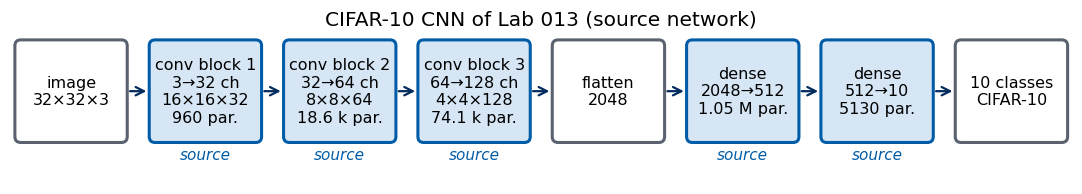

In [11]:
def cifar_block_shapes(body, x):
    # output shape of each convolutional block, computed with the layers of the body (evaluation mode)
    body.eval(); out, h = {}, x
    for i in (1, 2, 3):
        h = nnx.max_pool(nnx.relu(getattr(body, f"bn{i}")(getattr(body, f"conv{i}")(h))), (2, 2), strides=(2, 2))
        out[i] = fmt_shape(h.shape[1:])
    assert h.shape == body(x).shape                       # the same as the body's own forward pass
    return out

def cifar_body_blocks(body, status, tag=None):
    # one box per convolutional block, with channels, output shape and parameters read from the model
    sh = cifar_block_shapes(body, jnp.zeros((1, 32, 32, 3)))
    return [dict(name=f"conv block {i}", detail=f"{getattr(body, f'conv{i}').in_features}→{getattr(body, f'conv{i}').out_features} ch\n{sh[i]}",
                 params=count_params(getattr(body, f"conv{i}")) + count_params(getattr(body, f"bn{i}")), status=status, **({"tag": tag} if tag else {}))
            for i in (1, 2, 3)]

def dense_box(layer, status, tag=None, **kw):
    return dict(name="dense", detail=f"{layer.in_features}→{layer.out_features}", params=count_params(layer), status=status,
                **({"tag": tag} if tag else {}), **kw)

FLAT = fmt_shape((int(np.prod(cifar_cnn.body(jnp.zeros((1, 32, 32, 3))).shape[1:])),))
hd = cifar_cnn.head
TOTAL_CIFAR = draw_blocks([dict(name="image", detail="32×32×3", status="data")] + cifar_body_blocks(cifar_cnn.body, "source")
                          + [dict(name="flatten", detail=FLAT, status="data"), dense_box(hd.fc1, "source"), dense_box(hd.fc2, "source"),
                             dict(name=f"{hd.fc2.out_features} classes", detail="CIFAR-10", status="data")],
                          "CIFAR-10 CNN of Lab 013 (source network)", os.path.join(RESULTS, "Lab_014b_arch_cifar_source.png"))
assert TOTAL_CIFAR == count_params(cifar_cnn)

`nnx.tabulate` prints the same information module by module, with the output shape of every module for one input image and the parameters and batch statistics it holds.

In [12]:
cifar_cnn.eval()
print(nnx.tabulate(cifar_cnn, jnp.zeros((1, 32, 32, 3)), depth=2, console_kwargs={"force_terminal": False, "width": 150}))
print(f"diagram total {TOTAL_CIFAR:,} parameters = parameters in nnx.state {count_params(cifar_cnn):,}")

                                                          CifarCNN Summary                                                          
┏━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ path       ┃ type      ┃ inputs              ┃ outputs             ┃ BatchStat          ┃ Param                       ┃ RngState ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│            │ CifarCNN  │ float32[1,32,32,3]  │ float32[1,10]       │ 448 (1.8 KB)       │ 1,147,914 (4.6 MB)          │ 6 (36 B) │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body       │ CifarBody │ float32[1,32,32,3]  │ float32[1,4,4,128]  │ 448 (1.8 KB)       │ 93,696 (374.8 KB)           │ 4 (24 B) │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/conv1 │ Conv      │ float32[1,32,32,3]  │ float32[1,32,32,32] │                    │ bias: float32[32]           │          │
│            │           │                     │                     │                    │ kernel: float32[3,3,3,32]   │          │
│            │           │                     │                     │                    │                             │          │
│            │           │                     │                     │                    │ 896 (3.6 KB)                │          │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/bn1   │ BatchNorm │ float32[1,32,32,32] │ float32[1,32,32,32] │ mean: float32[32]  │ bias: float32[32]           │          │
│            │           │                     │                     │ var: float32[32]   │ scale: float32[32]          │          │
│            │           │                     │                     │                    │                             │          │
│            │           │                     │                     │ 64 (256 B)         │ 64 (256 B)                  │          │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/conv2 │ Conv      │ float32[1,16,16,32] │ float32[1,16,16,64] │                    │ bias: float32[64]           │          │
│            │           │                     │                     │                    │ kernel: float32[3,3,32,64]  │          │
│            │           │                     │                     │                    │                             │          │
│            │           │                     │                     │                    │ 18,496 (74.0 KB)            │          │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/bn2   │ BatchNorm │ float32[1,16,16,64] │ float32[1,16,16,64] │ mean: float32[64]  │ bias: float32[64]           │          │
│            │           │                     │                     │ var: float32[64]   │ scale: float32[64]          │          │
│            │           │                     │                     │                    │                             │          │
│            │           │                     │                     │ 128 (512 B)        │ 128 (512 B)                 │          │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/drop2 │ Dropout   │ float32[1,8,8,64]   │ float32[1,8,8,64]   │                    │                             │ 2 (12 B) │
├────────────┼───────────┼─────────────────────┼─────────────────────┼────────────────────┼─────────────────────────────┼──────────┤
│ body/con


diagram total 1,147,914 parameters = parameters in nnx.state 1,147,914


### Adapting the input

A frozen body can only be used on inputs that look, numerically, like the inputs it was trained on: three colour channels, $32\times32$ pixels, and each channel standardised with the CIFAR-10 mean $\mu_c$ and standard deviation $\sigma_c$ of that channel,
$$x_c\;\leftarrow\;\frac{x_c/255-\mu_c}{\sigma_c},\qquad c\in\{\text{red},\text{green},\text{blue}\}, \tag{4}$$
where $x_c$ is the integer value of channel $c$ of a pixel. BloodMNIST images already have three channels. We enlarge them from 28 to 32 pixels by bilinear interpolation (`jax.image.resize`), so that after three poolings the feature maps have the size $4\times4$ that the new layers expect, and we standardise them with the CIFAR-10 statistics, not with those of BloodMNIST: the first-layer kernels and the running averages of batch normalisation were fitted to inputs on that scale. Shapes: `uint8` $(N,28,28,3)$ → `float32` $(N,32,32,3)$. We prepare the largest labelled subset (6400 images) and the 3421 test images once.

In [13]:
def blood_as_cifar(X_raw):
    # uint8 (N, 28, 28, 3) -> float32 (N, 32, 32, 3), enlarged by bilinear interpolation, CIFAR-10 standardisation
    X = jnp.asarray(X_raw, dtype=jnp.float32) / 255
    X = jax.image.resize(X, (len(X), 32, 32, 3), method="bilinear")
    return ((np.asarray(X) - CIFAR_MEAN) / CIFAR_STD).astype(np.float32)

Xa_sub, ya_sub = blood_as_cifar(Xb_tr_raw[SUB[800]]), yb_tr[SUB[800]]     # largest labelled subset
Xa_te, ya_te = blood_as_cifar(Xb_te_raw), yb_te                            # full test set
assert Xa_sub.shape == (6400, 32, 32, 3) and Xa_te.shape == (3421, 32, 32, 3)
print("adapted blood cells:", Xa_sub.shape, " test:", Xa_te.shape)
print("channel means after CIFAR-10 standardisation:", Xa_te.mean((0, 1, 2)).round(2),
      " standard deviations:", Xa_te.std((0, 1, 2)).round(2))
print("CIFAR-10 test images for comparison:        ", Xc_te.mean((0, 1, 2)).round(2),
      " standard deviations:", Xc_te.std((0, 1, 2)).round(2))

adapted blood cells: (6400, 32, 32, 3)  test: (3421, 32, 32, 3)


channel means after CIFAR-10 standardisation: [1.22 0.73 0.95]  standard deviations: [0.85 0.97 0.42]


CIFAR-10 test images for comparison:         [0.01 0.01 0.01]  standard deviations: [1. 1. 1.]


Under the CIFAR-10 standardisation the blood-cell images do not have zero mean and unit variance: the channel means are 1.22, 0.73 and 0.95 and the standard deviation of the blue channel is only 0.42, against 0.01 and 1.0 for CIFAR-10 test images. Blood smears are bright, pink and much less varied in colour than photographs, so the frozen first layer sees inputs shifted far from what it was trained on. This mismatch is part of what the frozen body has to cope with; it disappears once the body is allowed to adapt.

### Freezing the body and adding new layers

In JAX nothing is frozen by a flag on the parameters: gradients and updates are taken only with respect to the parts we select. A filter `HEAD = nnx.All(nnx.Param, nnx.PathContains("head"))` selects the parameters whose path contains `head`. It is used twice. `nnx.value_and_grad(loss, argnums=nnx.DiffState(0, HEAD))` differentiates only with respect to these parameters, so no gradient of the body is computed; and `nnx.Optimizer(model, optax.adam(1e-3), wrt=HEAD)` holds the Adam state for, and applies updates to, these parameters only. An equivalent route keeps the optimiser on all parameters and gives the body a transformation that discards its updates, `optax.multi_transform({"train": optax.adam(1e-3), "freeze": optax.set_to_zero()}, labels)`, with a function that assigns a label to each parameter from its path; it is convenient when several groups need different learning rates, but it still computes the gradients of the body. Finally, the body must stay in evaluation mode, `model.body.eval()` after `model.train()`: batch normalisation would otherwise replace its running statistics (`nnx.BatchStat`, not parameters, updated in every training-mode forward pass) by statistics of blood-cell mini-batches, and dropout would be active.

The new layers are a dense layer from 2048 to 128 units, ReLU, dropout with rate 0.3, and a dense layer from 128 units to 8 outputs, with
$$2048\cdot128+128+128\cdot8+8=263\,304 \tag{5}$$
parameters (weights and biases of the two dense layers). To verify that the body stays fixed, all its variables (parameters and batch statistics) are copied before training and compared afterwards, and the sum of the absolute values of all entries is printed as a checksum.

In [14]:
class NewHead(nnx.Module):
    # new layers: flatten 2048 -> dense 128 -> ReLU -> dropout 0.3 -> dense 8
    def __init__(self, rngs, n_classes=8):
        self.fc1, self.drop, self.fc2 = nnx.Linear(2048, 128, rngs=rngs), nnx.Dropout(0.3, rngs=rngs), nnx.Linear(128, n_classes, rngs=rngs)
    def __call__(self, h):
        return self.fc2(self.drop(nnx.relu(self.fc1(h.reshape(h.shape[0], -1)))))

class TransferNet(nnx.Module):
    def __init__(self, body, rngs, n_classes=8):
        self.body, self.head = body, NewHead(rngs, n_classes)
    def __call__(self, x):
        return self.head(self.body(x))

HEAD = nnx.All(nnx.Param, nnx.PathContains("head"))          # filter: parameters of the new layers
step_head = make_step(HEAD)

def variables(module):
    # copy of all parameters and batch statistics as NumPy arrays
    return jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(module, (nnx.Param, nnx.BatchStat))))

def checksum(tree):
    return sum(float(np.abs(np.asarray(v, dtype=np.float64)).sum()) for v in jax.tree.leaves(tree))

def same_tree(a, b):
    return all(np.array_equal(u, v) for u, v in zip(jax.tree.leaves(a), jax.tree.leaves(b)))

demo = TransferNet(nnx.clone(cifar_cnn.body), nnx.Rngs(params=0, dropout=1))
n_train = sum(x.size for x in jax.tree.leaves(nnx.state(demo, HEAD)))
print(f"frozen network: {n_train} trainable parameters (new layers) of {count_params(demo)}; body {count_params(demo.body)} frozen")
assert n_train == 2048 * 128 + 128 + 128 * 8 + 8

frozen network: 263304 trainable parameters (new layers) of 357000; body 93696 frozen


The surgery on the CIFAR-10 network replaces its head. In the diagrams frozen blocks are grey and hatched (excluded from training: `requires_grad=False` in PyTorch, outside the optimiser's filter in JAX), removed blocks are red and crossed out, and new blocks are orange. The body keeps its trained weights and is frozen; the old head (dense 512 and dense 10 for the ten CIFAR-10 classes) is removed; a new head ends in 8 outputs for the eight cell types. The tables list, for every layer with parameters, the number of parameters and whether they are trained, before and after freezing.

before freezing: CIFAR-10 body + new layers (every parameter selected)
layer                   parameters  status
body.bn1                        64  trained
body.bn2                       128  trained
body.bn3                       256  trained
body.conv1                     896  trained
body.conv2                  18,496  trained
body.conv3                  73,856  trained
head.fc1                   262,272  trained
head.fc2                     1,032  trained
trainable                  357,000
frozen                           0

after freezing the body: filter HEAD selects the trained parameters
layer                   parameters  status
body.bn1                        64  frozen
body.bn2                       128  frozen
body.bn3                       256  frozen
body.conv1                     896  frozen
body.conv2                  18,496  frozen
body.conv3                  73,856  frozen
head.fc1                   262,272  trained
head.fc2                     1,032  trained
traina

per stage, after freezing (32×32 input)
stage           output shape  parameters  trainable
conv block 1        16×16×32         960  no
conv block 2          8×8×64      18,624  no
conv block 3         4×4×128      74,112  no
dense                    128     262,272  yes
dense                      8       1,032  yes
total                            357,000
trainable                        263,304
frozen                            93,696



saved results/Lab_014b_arch_cifar_frozen.png


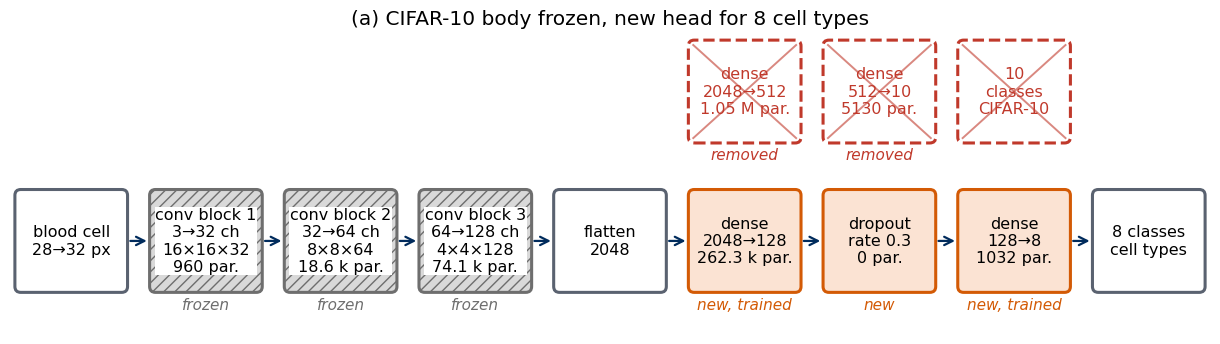

In [15]:
param_table(demo, nnx.Param, "before freezing: CIFAR-10 body + new layers (every parameter selected)", depth=None)
param_table(demo, HEAD, "after freezing the body: filter HEAD selects the trained parameters", depth=None)
SHB = cifar_block_shapes(demo.body, jnp.zeros((1, 32, 32, 3)))
CIFAR_STAGES = [(f"conv block {i}", SHB[i], [f"body.conv{i}", f"body.bn{i}"]) for i in (1, 2, 3)] + \
               [("dense", fmt_shape((demo.head.fc1.out_features,)), ["head.fc1"]), ("dense", fmt_shape((demo.head.fc2.out_features,)), ["head.fc2"])]
stage_table(demo, HEAD, CIFAR_STAGES, "per stage, after freezing (32×32 input)")

def new_head_boxes(model, tag=None):
    hd = model.head
    return [dict(name="flatten", detail=FLAT, status="data"), dense_box(hd.fc1, "new", tag),
            dict(name="dropout", detail=f"rate {hd.drop.rate}\n0 par.", status="new", tag="new"),
            dense_box(hd.fc2, "new", tag), dict(name=f"{hd.fc2.out_features} classes", detail="cell types", status="data")]

OLD_HEAD = [dense_box(cifar_cnn.head.fc1, "removed", "removed", row=1, at=5), dense_box(cifar_cnn.head.fc2, "removed", "removed", row=1, at=6),
            dict(name=f"{cifar_cnn.head.fc2.out_features}\nclasses", detail="CIFAR-10", status="removed", row=1, at=7, tag="")]
total = draw_blocks([dict(name="blood cell", detail="28→32 px", status="data")] + cifar_body_blocks(demo.body, "frozen")
                    + new_head_boxes(demo) + OLD_HEAD, "(a) CIFAR-10 body frozen, new head for 8 cell types",
                    os.path.join(RESULTS, "Lab_014b_arch_cifar_frozen.png"))
assert total == count_params(demo)

The same freezing can be written with `optax.multi_transform`. Every parameter receives a label from its path, `"trained"` for the new layers and `"frozen"` for the body; the trained group gets Adam, the frozen group `optax.set_to_zero()`, which replaces its updates by zeros. The optimiser now runs over all parameters, so gradients of the body are still computed and then discarded, which costs time but changes nothing else. One step with this optimiser leaves the body unchanged and moves the new layers. A third route, `jax.lax.stop_gradient(self.body(x))` in the forward pass, makes the gradient of the body zero already during differentiation; it fixes the choice inside the model, whereas a filter or a mask leaves the model untouched.

In [16]:
def labels_from_path(params):
    # "trained" for parameters under `head`, "frozen" otherwise
    return jax.tree_util.tree_map_with_path(
        lambda path, _: "trained" if any(getattr(k, "key", None) == "head" for k in path) else "frozen", params)

m_mask = TransferNet(nnx.clone(cifar_cnn.body), nnx.Rngs(params=0, dropout=1))
tx_mask = optax.multi_transform({"trained": optax.adam(1e-3), "frozen": optax.set_to_zero()}, labels_from_path)
opt_mask = nnx.Optimizer(m_mask, tx_mask, wrt=nnx.Param)
before_body, before_head = variables(m_mask.body), variables(m_mask.head)
m_mask.train(); m_mask.body.eval()
step_all(m_mask, opt_mask, jnp.asarray(Xa_sub[:64]), jnp.asarray(ya_sub[:64]))
assert same_tree(before_body, variables(m_mask.body)) and not same_tree(before_head, variables(m_mask.head))
labels = labels_from_path(nnx.to_pure_dict(nnx.state(m_mask, nnx.Param)))
print("labels:", {k: sorted(set(jax.tree.leaves(v))) for k, v in labels.items()})
print("one step with optax.multi_transform: body unchanged, new layers changed")

labels: {'body': ['frozen'], 'head': ['trained']}
one step with optax.multi_transform: body unchanged, new layers changed


### Three training regimes

The three regimes differ only in the starting point of the body and in which parameters move:

* (a) frozen: the CIFAR-10 body, frozen, with the new layers trained by Adam with learning rate $10^{-3}$;
* (b) random initialisation: the same architecture with a randomly initialised body, all parameters trained with learning rate $10^{-3}$ for twice as many steps as (a);
* (c) fine-tuning: model (a) after its training, with the body unfrozen and all parameters trained for as many steps again with learning rate $10^{-4}$, ten times smaller. Regimes (b) and (c) thus get the same total number of steps.

Every mini-batch has 64 images drawn at random from the labelled subset. A fixed number of steps for all budgets would leave the large subsets undertrained (300 steps are 240 passes over 80 images but only 3 over 6400), so the number of steps of (a) is 20 epochs, with a minimum of 300 steps: 300 steps for 10 and 100 cells per type, 2000 for 800. The mean training loss over the last 50 steps shows whether training has levelled off. Seeds are fixed, so the runs are reproducible; each model is tested on all 3421 test images.

For fine-tuning (c) the body is unfrozen again and the whole network is trained with the smaller learning rate $10^{-4}$, starting from model (a).

fine-tuning (c): filter nnx.Param selects everything, learning rate 1e-4
layer                   parameters  status
body.bn1                        64  trained
body.bn2                       128  trained
body.bn3                       256  trained
body.conv1                     896  trained
body.conv2                  18,496  trained
body.conv3                  73,856  trained
head.fc1                   262,272  trained
head.fc2                     1,032  trained
trainable                  357,000
frozen                           0

per stage, fine-tuning (c)
stage           output shape  parameters  trainable
conv block 1        16×16×32         960  yes
conv block 2          8×8×64      18,624  yes
conv block 3         4×4×128      74,112  yes
dense                    128     262,272  yes
dense                      8       1,032  yes
total                            357,000
trainable                        357,000
frozen                                 0



saved results/Lab_014b_arch_cifar_finetune.png


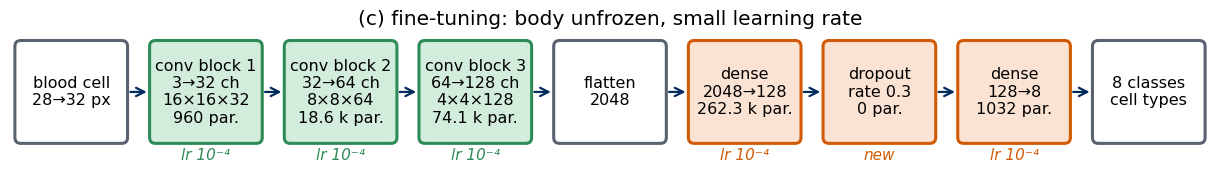

In [17]:
param_table(demo, nnx.Param, "fine-tuning (c): filter nnx.Param selects everything, learning rate 1e-4", depth=None)
stage_table(demo, nnx.Param, CIFAR_STAGES, "per stage, fine-tuning (c)")
total = draw_blocks([dict(name="blood cell", detail="28→32 px", status="data")] + cifar_body_blocks(demo.body, "unfrozen", "lr 10⁻⁴")
                    + new_head_boxes(demo, "lr 10⁻⁴"), "(c) fine-tuning: body unfrozen, small learning rate",
                    os.path.join(RESULTS, "Lab_014b_arch_cifar_finetune.png"))
assert total == count_params(demo)

In [18]:
EPOCHS_A, MIN_STEPS_A = 20, 300                 # (a): 20 epochs, at least 300 steps; (b) twice as many; (c) as many again
METHODS_A = {"frozen": "(a) frozen CIFAR-10 body + new layers",
             "random": "(b) random initialisation",
             "finetune": "(c) (a) + fine-tuning, learning rate / 10"}
acc_A = {m: [] for m in METHODS_A}; time_A = {m: [] for m in METHODS_A}; models_A = {}

for n in BUDGETS:
    Xs, ys = Xa_sub[POS[n]], ya_sub[POS[n]]
    S = n_steps(n, EPOCHS_A, MIN_STEPS_A)
    # (a) frozen body, new layers trained
    ma = TransferNet(nnx.clone(cifar_cnn.body), nnx.Rngs(params=0, dropout=1))
    before = variables(ma.body)
    ma.train(); ma.body.eval()                                           # body: batch norm statistics fixed, no dropout
    t_a, l_a = train_steps(ma, nnx.Optimizer(ma, optax.adam(1e-3), wrt=HEAD), step_head, Xs, ys, S)
    assert same_tree(before, variables(ma.body)), "the frozen body changed"
    # (b) the same architecture, random initialisation, everything trained
    mb = TransferNet(CifarBody(True, nnx.Rngs(params=0, dropout=1)), nnx.Rngs(params=0, dropout=1))
    mb.train()
    t_b, l_b = train_steps(mb, nnx.Optimizer(mb, optax.adam(1e-3), wrt=nnx.Param), step_all, Xs, ys, 2 * S)
    # (c) continue from (a): unfreeze the body, train everything with a ten times smaller learning rate
    mc = nnx.clone(ma)
    mc.train()
    t_c, l_c = train_steps(mc, nnx.Optimizer(mc, optax.adam(1e-4), wrt=nnx.Param), step_all, Xs, ys, S, seed=1)
    t_c += t_a
    assert not same_tree(before, variables(mc.body))
    for m, model, t in [("frozen", ma, t_a), ("random", mb, t_b), ("finetune", mc, t_c)]:
        acc_A[m].append(accuracy(model, Xa_te, ya_te)); time_A[m].append(t)
        if n == 100: models_A[m] = model
    print(f"n = {n}: {S} steps ({S * 64 / (8 * n):.0f} epochs) for (a), {2 * S} for (b), {S} more for (c);"
          f" body checksum before {checksum(before):.6f}, after {checksum(variables(ma.body)):.6f}")
    print(f"   final training loss  (a) {l_a:.3f}   (b) {l_b:.3f}   (c) {l_c:.3f}")
    print(f"   test accuracy        (a) {100 * acc_A['frozen'][-1]:.1f}%   (b) {100 * acc_A['random'][-1]:.1f}%   (c) {100 * acc_A['finetune'][-1]:.1f}%")

n = 10: 300 steps (240 epochs) for (a), 600 for (b), 300 more for (c); body checksum before 4290.107254, after 4290.107254
   final training loss  (a) 0.018   (b) 0.008   (c) 0.022
   test accuracy        (a) 66.3%   (b) 71.3%   (c) 67.1%


n = 100: 300 steps (24 epochs) for (a), 600 for (b), 300 more for (c); body checksum before 4290.107254, after 4290.107254
   final training loss  (a) 0.269   (b) 0.097   (c) 0.312
   test accuracy        (a) 83.7%   (b) 81.2%   (c) 82.5%


n = 800: 2000 steps (20 epochs) for (a), 4000 for (b), 2000 more for (c); body checksum before 4290.107254, after 4290.107254
   final training loss  (a) 0.224   (b) 0.093   (c) 0.299
   test accuracy        (a) 90.1%   (b) 94.0%   (c) 91.1%


In [19]:
print(f"{'cells per type':>14s} | " + " | ".join(f"{METHODS_A[m]:>40s}" for m in METHODS_A))
for i, n in enumerate(BUDGETS):
    print(f"{n:14d} | " + " | ".join(f"{100 * acc_A[m][i]:33.1f}% ({time_A[m][i]:3.0f} s)" for m in METHODS_A))

cells per type |    (a) frozen CIFAR-10 body + new layers |                (b) random initialisation | (c) (a) + fine-tuning, learning rate / 10
            10 |                              66.3% ( 47 s) |                              71.3% (419 s) |                              67.1% (320 s)
           100 |                              83.7% ( 13 s) |                              81.2% ( 87 s) |                              82.5% ( 94 s)
           800 |                              90.1% ( 55 s) |                              94.0% (733 s) |                              91.1% (751 s)


saved results/Lab_014b_transfer_cifar_cnn_blood.png


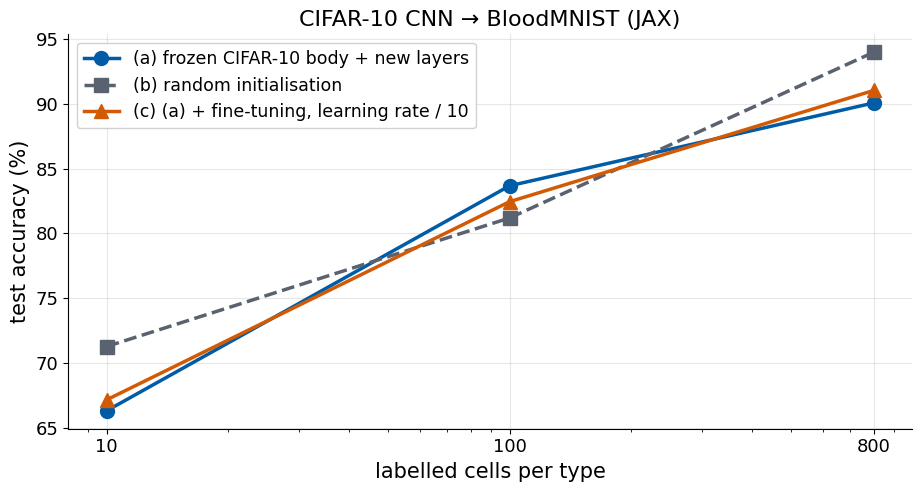

In [20]:
def plot_budget(curves, title, path=None):
    # curves: list of (label, accuracies at BUDGETS, colour, marker, linestyle); large fonts for slides
    with plt.rc_context({"font.size": 16, "legend.fontsize": 12.5}):
        fig, ax = plt.subplots(figsize=(9.5, 5.2))
        for lab, acc, c, mk, ls in curves:
            ax.plot(BUDGETS, 100 * np.asarray(acc), marker=mk, ls=ls, color=c, lw=2.5, ms=10, label=lab)
        ax.set_xscale("log"); ax.set_xticks(BUDGETS); ax.set_xticklabels([str(b) for b in BUDGETS])
        ax.set_xlabel("labelled cells per type"); ax.set_ylabel("test accuracy (%)")
        ax.set_title(title); ax.grid(alpha=0.3); ax.legend(loc="best", framealpha=0.9)
        fig.tight_layout()
        if path: fig.savefig(path, dpi=200); print("saved", path)
        plt.show()

plot_budget([(METHODS_A["frozen"], acc_A["frozen"], UJBlue, "o", "-"),
             (METHODS_A["random"], acc_A["random"], UJGray, "s", "--"),
             (METHODS_A["finetune"], acc_A["finetune"], DSOrange, "^", "-")],
            "CIFAR-10 CNN → BloodMNIST (JAX)", os.path.join(RESULTS, "Lab_014b_transfer_cifar_cnn_blood.png"))

Transfer from our own CIFAR-10 network gives a mixed result on blood cells. Training the same architecture from random initialisation (b) is best at 10 and at 800 cells per type, 71.3% and 94.0%, against 66.3% and 90.1% for the frozen body (a) and 67.1% and 91.1% after fine-tuning (c). At 100 cells per type the frozen body is slightly ahead, 83.7% against 81.2% for (b) and 82.5% for (c). The checksum of the frozen body is the same before and after training (4290.107254), so the optimiser indeed left it untouched. The PyTorch version of this notebook gives the same picture at 10 and 800 cells per type and a small lead of (b) at 100, so the ranking at 100 cells per type is not robust. Overall, a small source network trained on 10 000 photographs is not a strong prior for stained cells.

### Confusion matrices

The confusion matrix counts $C_{ab}$, the number of test cells of true type $a$ predicted as type $b$; colours show each row divided by its sum, so the diagonal is the recall of each type. We show the three models trained on 100 cells per type and save their weights.

(a) frozen CIFAR-10 body + new layers      recall per type [0.67 0.93 0.86 0.59 0.89 0.79 0.91 0.99]; most frequent error immature granulocyte -> monocyte (107 of 579)
   saved results/Lab_014b_cifar_cnn_frozen_100_per_type.msgpack


(b) random initialisation                  recall per type [0.79 0.96 0.66 0.35 0.92 0.9  0.95 1.  ]; most frequent error immature granulocyte -> monocyte (245 of 579)
   saved results/Lab_014b_cifar_cnn_random_100_per_type.msgpack


(c) (a) + fine-tuning, learning rate / 10  recall per type [0.78 0.91 0.85 0.53 0.82 0.82 0.89 0.99]; most frequent error immature granulocyte -> monocyte (148 of 579)
   saved results/Lab_014b_cifar_cnn_finetune_100_per_type.msgpack


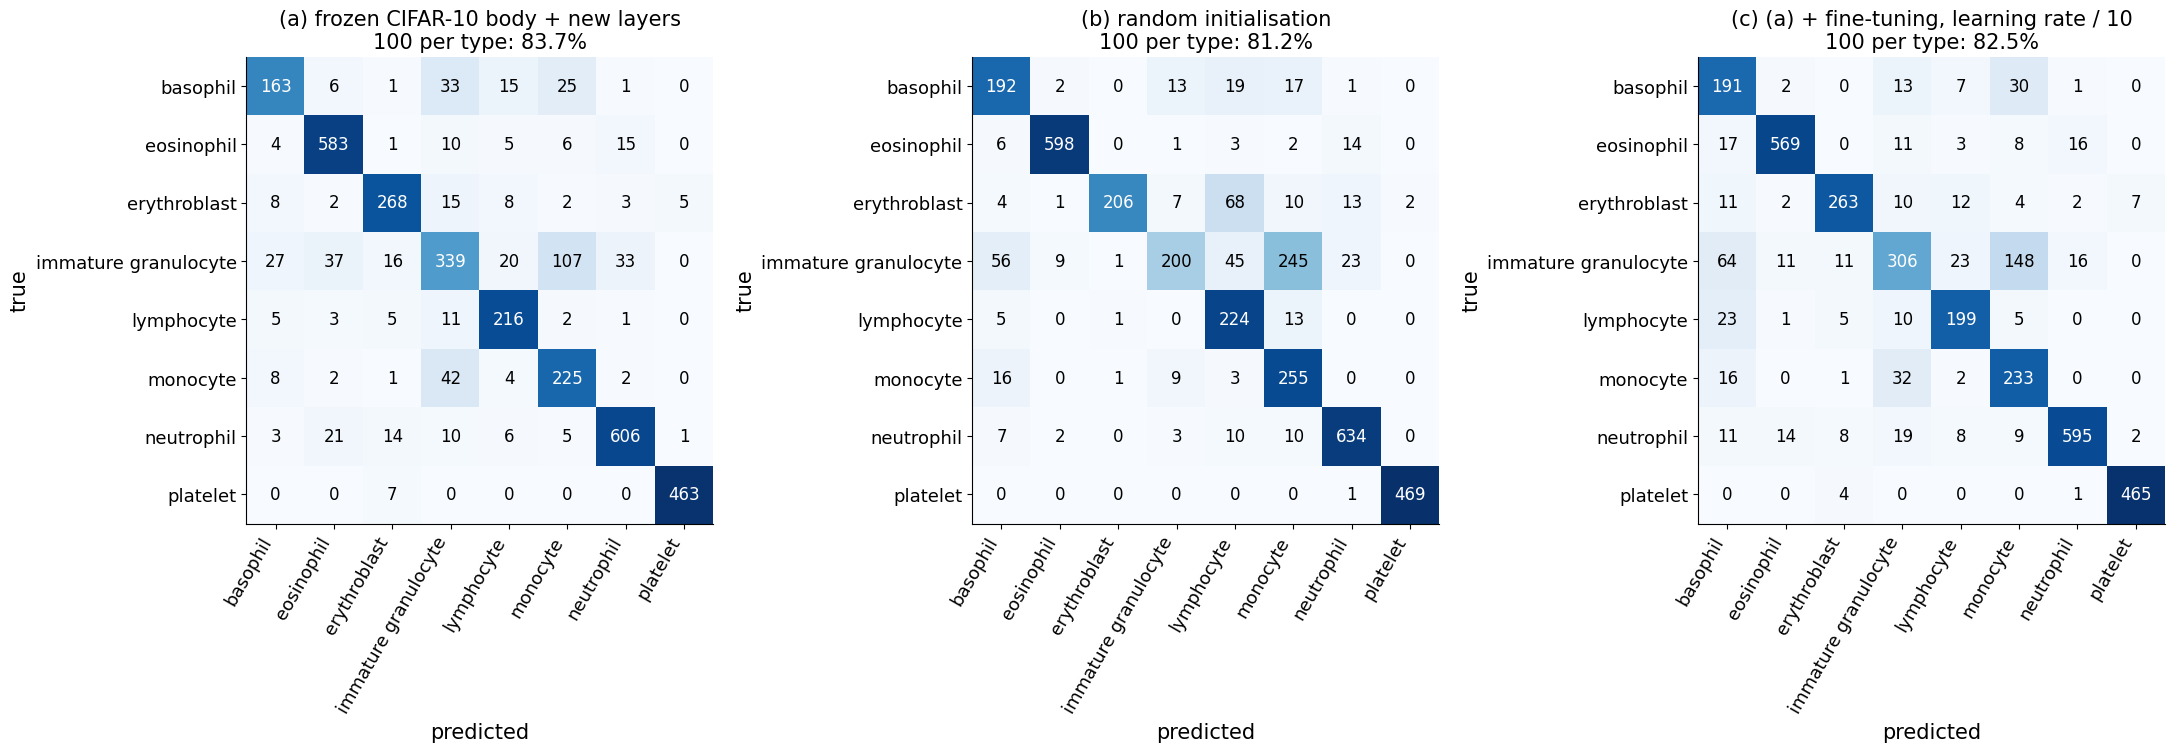

In [21]:
def confusion_matrix(y_true, y_pred, n=8):
    cm = np.zeros((n, n), dtype=int)
    np.add.at(cm, (np.asarray(y_true), np.asarray(y_pred)), 1)
    return cm

def plot_confusion(ax, cm, labels, title):
    # rows: true class, columns: predicted class; colour = fraction of the row, numbers = counts
    frac = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for a in range(len(labels)):
        for b in range(len(labels)):
            ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=12, color="white" if frac[a, b] > 0.5 else "black")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=13)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=13)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=15)

def most_confused(cm):
    off = cm - np.diag(np.diag(cm)); a, b = np.unravel_index(off.argmax(), off.shape)
    return f"{BLOOD_TYPES[a]} -> {BLOOD_TYPES[b]} ({off[a, b]} of {cm[a].sum()})"

fig, axes = plt.subplots(1, 3, figsize=(22, 8))
for ax, m in zip(axes, METHODS_A):
    pred = predict(models_A[m], Xa_te).argmax(1)
    cm = confusion_matrix(yb_te, pred)
    plot_confusion(ax, cm, BLOOD_TYPES, f"{METHODS_A[m]}\n100 per type: {100 * (pred == yb_te).mean():.1f}%")
    print(f"{METHODS_A[m]:42s} recall per type {np.round(np.diag(cm) / cm.sum(1), 2)}; most frequent error {most_confused(cm)}")
    print("   saved", save(models_A[m], os.path.join(RESULTS, f"Lab_014b_cifar_cnn_{m}_100_per_type.msgpack")))
plt.tight_layout(); plt.show()

The weakest class is the same in all three models: immature granulocytes, with recall 0.59, 0.35 and 0.53 for (a), (b) and (c), confused mostly with monocytes (107, 245 and 148 of 579 test cells). These two types are morphologically closest: large cells with a big nucleus and granular cytoplasm. The randomly initialised network (b) is the most one-sided: it recognises neutrophils, eosinophils and platelets best (0.95, 0.96 and 1.0) but only a third of the immature granulocytes. Platelets, small and anucleate, are recognised almost perfectly by every model.

## 3. A pretrained ResNet-18

The second source network is ResNet-18, the smallest residual network of K. He, X. Zhang, S. Ren and J. Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016, pp. 770–778, [doi:10.1109/CVPR.2016.90](https://doi.org/10.1109/CVPR.2016.90), [arXiv:1512.03385](https://arxiv.org/abs/1512.03385), with the weights published in `torchvision`, trained on ImageNet-1k (about 1.28 million photographs in 1000 classes, at $224\times224$ pixels). Compared with the CIFAR-10 network of Section 2 it has a hundred times more parameters and was trained on a hundred times more images; the question is whether features learned on photographs of dogs, cars and mushrooms help with blood cells.

ImageNet (J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li, L. Fei-Fei, *ImageNet: A large-scale hierarchical image database*, CVPR 2009, pp. 248–255, [doi:10.1109/CVPR.2009.5206848](https://doi.org/10.1109/CVPR.2009.5206848)) is a collection of photographs organised by the noun hierarchy of WordNet. The subset used for the ImageNet Large Scale Visual Recognition Challenge (O. Russakovsky et al., International Journal of Computer Vision 115, 211 (2015), [doi:10.1007/s11263-015-0816-y](https://doi.org/10.1007/s11263-015-0816-y), [arXiv:1409.0575](https://arxiv.org/abs/1409.0575)), called ImageNet-1k, has 1 281 167 training images, 50 000 validation images and 1000 classes, listed on [image-net.org](https://www.image-net.org/download.php). The classes are everyday objects, animals, plants, food and scenes, with a strong share of fine-grained categories such as breeds of dogs; photographs vary in size and are typically a few hundred pixels wide. The images may be used for non-commercial research and education under the ImageNet terms of access. A pretrained ResNet-18 has therefore seen many textures, colours and shapes, but no microscope images of stained blood. Twenty class names drawn at random give an impression of its world.

### ResNet-18 in Flax

Flax offers no collection of pretrained image networks comparable to `torchvision.models`, so we write the architecture ourselves, layer for layer as in `torchvision`, and then copy the published weights into it. The network has a stem (a $7\times7$ convolution with stride 2, batch normalisation, ReLU, and a $3\times3$ max pooling with stride 2), four stages `layer1` to `layer4` of two residual blocks each, global average pooling, and a dense layer `fc` from 512 features to 1000 classes. A residual block computes
$$x\;\mapsto\;\mathrm{ReLU}\big(x+F(x)\big), \tag{6}$$
where $F$ is two $3\times3$ convolutions with batch normalisation; when a block halves the image size and doubles the channels, the shortcut passes through a $1\times1$ convolution with stride 2 and batch normalisation, so that both terms of the sum have the same shape.

Every detail has to match PyTorch for the weights to mean the same thing: convolutions without bias, explicit padding $(3,3)$ for the stem and $(1,1)$ for the $3\times3$ convolutions (Flax's `"SAME"` padding would place the extra row differently for stride 2), max pooling with padding 1, batch normalisation with $\epsilon=10^{-5}$. The methods `trunk` (up to `layer3`) and `pooled` (`layer4` and average pooling) are used later to store intermediate results.

In [22]:
class BasicBlock(nnx.Module):
    # residual block: ReLU(x + bn2(conv2(ReLU(bn1(conv1(x)))))); 1x1 convolution on the shortcut when the shape changes
    def __init__(self, cin, cout, stride, rngs):
        bn = lambda c: nnx.BatchNorm(c, momentum=0.9, epsilon=1e-5, rngs=rngs)       # PyTorch: momentum 0.1, eps 1e-5
        self.conv1 = nnx.Conv(cin, cout, (3, 3), strides=stride, padding=((1, 1), (1, 1)), use_bias=False, rngs=rngs)
        self.bn1 = bn(cout)
        self.conv2 = nnx.Conv(cout, cout, (3, 3), strides=1, padding=((1, 1), (1, 1)), use_bias=False, rngs=rngs)
        self.bn2 = bn(cout)
        if stride != 1 or cin != cout:
            self.down_conv = nnx.Conv(cin, cout, (1, 1), strides=stride, padding="VALID", use_bias=False, rngs=rngs)
            self.down_bn = bn(cout)
        else:
            self.down_conv, self.down_bn = None, None
    def __call__(self, x):
        h = nnx.relu(self.bn1(self.conv1(x)))
        h = self.bn2(self.conv2(h))
        shortcut = x if self.down_conv is None else self.down_bn(self.down_conv(x))
        return nnx.relu(h + shortcut)

class ResNet18(nnx.Module):
    def __init__(self, n_classes, rngs):
        self.conv1 = nnx.Conv(3, 64, (7, 7), strides=2, padding=((3, 3), (3, 3)), use_bias=False, rngs=rngs)
        self.bn1 = nnx.BatchNorm(64, momentum=0.9, epsilon=1e-5, rngs=rngs)
        self.layer1 = nnx.List([BasicBlock(64, 64, 1, rngs), BasicBlock(64, 64, 1, rngs)])
        self.layer2 = nnx.List([BasicBlock(64, 128, 2, rngs), BasicBlock(128, 128, 1, rngs)])
        self.layer3 = nnx.List([BasicBlock(128, 256, 2, rngs), BasicBlock(256, 256, 1, rngs)])
        self.layer4 = nnx.List([BasicBlock(256, 512, 2, rngs), BasicBlock(512, 512, 1, rngs)])
        self.fc = nnx.Linear(512, n_classes, rngs=rngs)
    def stem(self, x):                          # (N, H, W, 3) -> (N, H/4, W/4, 64)
        h = nnx.relu(self.bn1(self.conv1(x)))
        return nnx.max_pool(h, (3, 3), strides=(2, 2), padding=((1, 1), (1, 1)))
    def trunk(self, x):                         # up to layer3: (N, H/16, W/16, 256)
        h = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3):
            for block in layer: h = block(h)
        return h
    def pooled(self, h3):                       # layer4 and global average pooling: (N, 512)
        for block in self.layer4: h3 = block(h3)
        return h3.mean(axis=(1, 2))
    def __call__(self, x):
        return self.fc(self.pooled(self.trunk(x)))

jresnet = ResNet18(1000, nnx.Rngs(0))
print("parameters of the Flax ResNet-18:", count_params(jresnet))

parameters of the Flax ResNet-18: 11689512


### Conversion of the torchvision weights

`torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)` downloads the weights (about 45 MB, to `~/.cache/torch/hub/checkpoints/`). Its `state_dict` holds 122 tensors, and each has a counterpart in the Flax model. Three conventions differ:

* convolution kernels are stored as $(C_{\text{out}},C_{\text{in}},k_h,k_w)$ in PyTorch and $(k_h,k_w,C_{\text{in}},C_{\text{out}})$ in Flax, hence `w.transpose(2, 3, 1, 0)`;
* dense weights are $(n_{\text{out}},n_{\text{in}})$ in PyTorch and $(n_{\text{in}},n_{\text{out}})$ in Flax, hence a transpose;
* batch normalisation `weight`, `bias`, `running_mean`, `running_var` become `scale`, `bias`, `mean`, `var`; the counter `num_batches_tracked` has no counterpart and is not needed.

The conversion copies every tensor and asserts that none is left over. The decisive test is functional: the PyTorch network and the Flax network must give the same 1000 logits for the same images (in PyTorch layout $(N,3,64,64)$ and in Flax layout $(N,64,64,3)$), up to float32 rounding.

In [23]:
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
tresnet = torchvision.models.resnet18(weights=weights).eval()      # downloads about 45 MB on the first call
sd = {k: v.numpy() for k, v in tresnet.state_dict().items()}       # name -> NumPy array
print("ImageNet results stored with the weights:", weights.meta["_metrics"])
print("twenty ImageNet classes drawn at random:", ", ".join(np.random.default_rng(1).choice(weights.meta["categories"], 20, replace=False)))
print("number of PyTorch tensors:", len(sd), "| e.g.", {k: sd[k].shape for k in ["conv1.weight", "bn1.running_var", "layer2.0.downsample.0.weight", "fc.weight"]})

def copy_conv(conv, w):
    # PyTorch (out, in, kh, kw) -> Flax (kh, kw, in, out)
    assert conv.kernel.shape == w.transpose(2, 3, 1, 0).shape
    conv.kernel[...] = jnp.asarray(w.transpose(2, 3, 1, 0))

def copy_bn(bn, prefix):
    bn.scale[...] = jnp.asarray(sd[prefix + ".weight"]); bn.bias[...] = jnp.asarray(sd[prefix + ".bias"])
    bn.mean[...] = jnp.asarray(sd[prefix + ".running_mean"]); bn.var[...] = jnp.asarray(sd[prefix + ".running_var"])

def convert(model):
    used = set()
    def conv(c, name): copy_conv(c, sd[name]); used.add(name)
    def bn(b, prefix): copy_bn(b, prefix); used.update(prefix + s for s in [".weight", ".bias", ".running_mean", ".running_var", ".num_batches_tracked"])
    conv(model.conv1, "conv1.weight"); bn(model.bn1, "bn1")
    for l in range(1, 5):
        for i, block in enumerate(getattr(model, f"layer{l}")):
            p = f"layer{l}.{i}"
            conv(block.conv1, p + ".conv1.weight"); bn(block.bn1, p + ".bn1")
            conv(block.conv2, p + ".conv2.weight"); bn(block.bn2, p + ".bn2")
            if block.down_conv is not None:
                conv(block.down_conv, p + ".downsample.0.weight"); bn(block.down_bn, p + ".downsample.1")
    model.fc.kernel[...] = jnp.asarray(sd["fc.weight"].T); model.fc.bias[...] = jnp.asarray(sd["fc.bias"])   # (out, in) -> (in, out)
    used.update(["fc.weight", "fc.bias"])
    assert used == set(sd), f"tensors not copied: {set(sd) - used}"
    return model

convert(jresnet)
print("all", len(sd), "PyTorch tensors copied")

ImageNet results stored with the weights: {'ImageNet-1K': {'acc@1': 69.758, 'acc@5': 89.078}}
twenty ImageNet classes drawn at random: Great Dane, maraca, eft, red wolf, dowitcher, printer, buckle, broccoli, quail, Band Aid, mashed potato, clog, toilet seat, space shuttle, leatherback turtle, steel drum, fly, ambulance, Leonberg, entertainment center
number of PyTorch tensors: 122 | e.g. {'conv1.weight': (64, 3, 7, 7), 'bn1.running_var': (64,), 'layer2.0.downsample.0.weight': (128, 64, 1, 1), 'fc.weight': (1000, 512)}


all 122 PyTorch tensors copied


In [24]:
T_ = weights.transforms()
IMNET_MEAN, IMNET_STD = np.array(T_.mean, np.float32), np.array(T_.std, np.float32)
def blood_as_imagenet(X_raw):
    # uint8 (N, 64, 64, 3) -> float32 (N, 64, 64, 3) standardised with the ImageNet statistics (channels last)
    return ((X_raw.astype(np.float32) / 255 - IMNET_MEAN) / IMNET_STD).astype(np.float32)

x_check = blood_as_imagenet(b64["test_images"][:32])                              # (32, 64, 64, 3)
with torch.no_grad():
    logits_torch = tresnet(torch.from_numpy(x_check.transpose(0, 3, 1, 2))).numpy()   # PyTorch wants (N, 3, 64, 64)
jresnet.eval()
logits_flax = np.asarray(logits_fn(jresnet, jnp.asarray(x_check)))
diff = np.abs(logits_torch - logits_flax).max()
print(f"32 blood cells, 1000 ImageNet logits: max |PyTorch - Flax| = {diff:.2e}  (largest |logit| {np.abs(logits_torch).max():.1f})")
print("same top-1 class for all 32 images:", np.array_equal(logits_torch.argmax(1), logits_flax.argmax(1)))
assert diff < 1e-3

32 blood cells, 1000 ImageNet logits: max |PyTorch - Flax| = 2.48e-05  (largest |logit| 42.1)
same top-1 class for all 32 images: True


All 122 tensors of the torchvision ResNet-18 are copied into the Flax model, including the running statistics of the batch normalisation. On 32 blood cells the 1000 ImageNet logits of the two implementations differ by at most 2.5 × 10⁻⁵, against logits of up to 42, and the predicted class is the same for every image: the JAX network is the same function as the PyTorch one, up to floating-point rounding. The weights reach 69.8% top-1 accuracy on the ImageNet validation set, as stored with them.

### Architecture and parameter count

We count the parameters of each stage and follow the shape of one input of $224\times224$ pixels, the ImageNet size, and of $64\times64$ pixels, the BloodMNIST size.

In [25]:
STAGES = ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]
print(f"{'stage':8s} {'parameters':>11s} {'fraction':>9s}")
for s in STAGES:
    k = count_params(getattr(jresnet, s))
    print(f"{s:8s} {k:11d} {100 * k / count_params(jresnet):8.1f}%")
assert sum(count_params(getattr(jresnet, s)) for s in STAGES) == count_params(jresnet) == weights.meta["num_params"]

def stage_shapes(model, size):
    model.eval()
    x = jnp.zeros((1, size, size, 3)); out = {}
    x = model.stem(x); out["stem"] = x.shape
    for s in ["layer1", "layer2", "layer3", "layer4"]:
        for block in getattr(model, s): x = block(x)
        out[s] = x.shape
    out["avgpool"] = x.mean(axis=(1, 2)).shape
    return out

s224, s64 = stage_shapes(jresnet, 224), stage_shapes(jresnet, 64)
print(f"\n{'after':8s} {'224 x 224 input':>20s} {'64 x 64 input':>20s}")
for k in s224: print(f"{k:8s} {str(s224[k]):>20s} {str(s64[k]):>20s}")

stage     parameters  fraction
conv1           9408      0.1%
bn1              128      0.0%
layer1        147968      1.3%
layer2        525568      4.5%
layer3       2099712     18.0%
layer4       8393728     71.8%
fc            513000      4.4%



after         224 x 224 input        64 x 64 input
stem          (1, 56, 56, 64)      (1, 16, 16, 64)
layer1        (1, 56, 56, 64)      (1, 16, 16, 64)
layer2       (1, 28, 28, 128)       (1, 8, 8, 128)
layer3       (1, 14, 14, 256)       (1, 4, 4, 256)
layer4         (1, 7, 7, 512)       (1, 2, 2, 512)
avgpool              (1, 512)             (1, 512)


Seventy-two per cent of the 11.7 million parameters sit in `layer4`, and only 0.1% in the stem; the output layer for 1000 classes holds another 4.4%. On a $224\times224$ image the last stage works on a $7\times7$ grid; on our $64\times64$ cells it works on a $2\times2$ grid, so each of its units sees almost the whole cell. Average pooling turns both into the same 512 features.

The block diagram summarises the network as it was trained on ImageNet: stem, four residual stages, average pooling and the output layer with 1000 classes, each block with the number of its parameters. Seventy-two per cent of the parameters sit in `layer4`.

saved results/Lab_014b_arch_resnet18_source.png


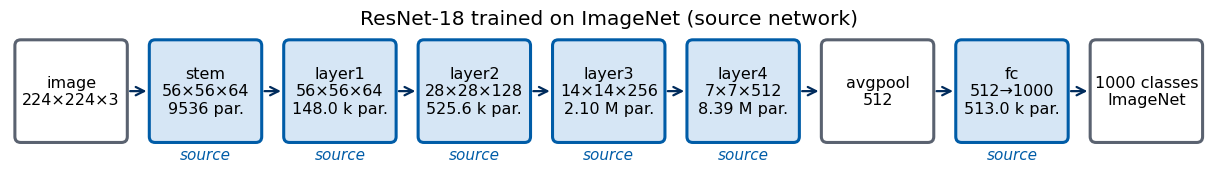

In [26]:
STAGE_MODS = [("stem", ["conv1", "bn1"]), ("layer1", ["layer1"]), ("layer2", ["layer2"]), ("layer3", ["layer3"]), ("layer4", ["layer4"])]

def resnet_stage_shapes(model, size):
    # output shape after the stem and after each stage, computed with the model's own modules (evaluation mode)
    model.eval(); x = jnp.zeros((1, size, size, 3))
    h = model.stem(x); out = {"stem": fmt_shape(h.shape[1:])}
    for s in ["layer1", "layer2", "layer3", "layer4"]:
        for block in getattr(model, s): h = block(h)
        out[s] = fmt_shape(h.shape[1:])
    out["avgpool"] = fmt_shape(h.mean(axis=(1, 2)).shape[1:])
    assert np.allclose(model.fc(h.mean(axis=(1, 2))), model(x), atol=1e-4)    # the same as the model's own forward pass
    return out

SH = {size: resnet_stage_shapes(jresnet, size) for size in (224, 64)}

def resnet_blocks(model, status_of, tag_of=lambda s: None, size=64):
    # one box per stage: output shape and parameter count read from the model
    return [dict(name=s, detail=SH[size][s], params=sum(count_params(getattr(model, m)) for m in mods), status=status_of(s),
                 **({"tag": tag_of(s)} if tag_of(s) else {})) for s, mods in STAGE_MODS]

def fc_box(model, status, tag=None, **kw):
    return dict(name="fc", detail=f"{model.fc.in_features}→{model.fc.out_features}", params=count_params(model.fc), status=status,
                **({"tag": tag} if tag else {}), **kw)

TOTAL_RESNET = draw_blocks([dict(name="image", detail="224×224×3", status="data")] + resnet_blocks(jresnet, lambda s: "source", size=224)
                           + [dict(name="avgpool", detail=SH[224]["avgpool"], status="data"), fc_box(jresnet, "source"),
                              dict(name=f"{jresnet.fc.out_features} classes", detail="ImageNet", status="data")],
                           "ResNet-18 trained on ImageNet (source network)", os.path.join(RESULTS, "Lab_014b_arch_resnet18_source.png"))
assert TOTAL_RESNET == count_params(jresnet) == weights.meta["num_params"]

`nnx.tabulate` prints the same information module by module, with the output shape of every module for one input image and the parameters and batch statistics it holds.

In [27]:
jresnet.eval()
print(nnx.tabulate(jresnet, jnp.zeros((1, 64, 64, 3)), depth=1, console_kwargs={"force_terminal": False, "width": 150}))
print(f"diagram total {TOTAL_RESNET:,} parameters = parameters in nnx.state {count_params(jresnet):,}")

                                                 ResNet18 Summary                                                 
┏━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path   ┃ type      ┃ inputs              ┃ outputs             ┃ BatchStat         ┃ Param                     ┃
┡━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ stem   │ ResNet18  │ float32[1,64,64,3]  │ float32[1,16,16,64] │ 9,600 (38.4 KB)   │ 11,689,512 (46.8 MB)      │
├────────┼───────────┼─────────────────────┼─────────────────────┼───────────────────┼───────────────────────────┤
│ conv1  │ Conv      │ float32[1,64,64,3]  │ float32[1,32,32,64] │                   │ kernel: float32[7,7,3,64] │
│        │           │                     │                     │                   │                           │
│        │           │                     │                     │                   │ 9,408 (37.6 KB)           │
├────────┼───────────┼─────────────────────┼─────────────────────┼───────────────────┼───────────────────────────┤
│ bn1    │ BatchNorm │ float32[1,32,32,64] │ float32[1,32,32,64] │ mean: float32[64] │ bias: float32[64]         │
│        │           │                     │                     │ var: float32[64]  │ scale: float32[64]        │
│        │           │                     │                     │                   │                           │
│        │           │                     │                     │ 128 (512 B)       │ 128 (512 B)               │
├────────┼───────────┼─────────────────────┼─────────────────────┼───────────────────┼───────────────────────────┤
│ pooled │ ResNet18  │ float32[1,4,4,256]  │ float32[1,512]      │ 9,600 (38.4 KB)   │ 11,689,512 (46.8 MB)      │
├────────┼───────────┼─────────────────────┼─────────────────────┼───────────────────┼───────────────────────────┤
│ fc     │ Linear    │ float32[1,512]      │ float32[1,1000]     │                   │ bias: float32[1000]       │
│        │           │                     │                     │                   │ kernel: float32[512,1000] │
│        │           │                     │                     │                   │                           │
│        │           │                     │                     │                   │ 513,000 (2.1 MB)          │
├────────┼───────────┼─────────────────────┼─────────────────────┼───────────────────┼───────────────────────────┤
│        │           │                     │               Total │ 9,600 (38.4 KB)   │ 11,689,512 (46.8 MB)      │
└────────┴───────────┴─────────────────────┴─────────────────────┴───────────────────┴───────────────────────────┘
                                                                                                                  
                                      Total Parameters: 11,699,112 (46.8 MB)                                      


diagram total 11,689,512 parameters = parameters in nnx.state 11,689,512


### First-layer kernels

The converted `jresnet.conv1.kernel` has shape $(7,7,3,64)$: 64 kernels, each with one $7\times7$ slice per input colour. Reordered to $(64,7,7,3)$ and each rescaled to $[0,1]$, a kernel can be shown as a small colour image. To quantify what we see, we compute for every kernel the mean correlation between its red, green and blue slices: close to 1 for a kernel that treats the three colours alike (a brightness pattern), small or negative for a kernel that compares colours.

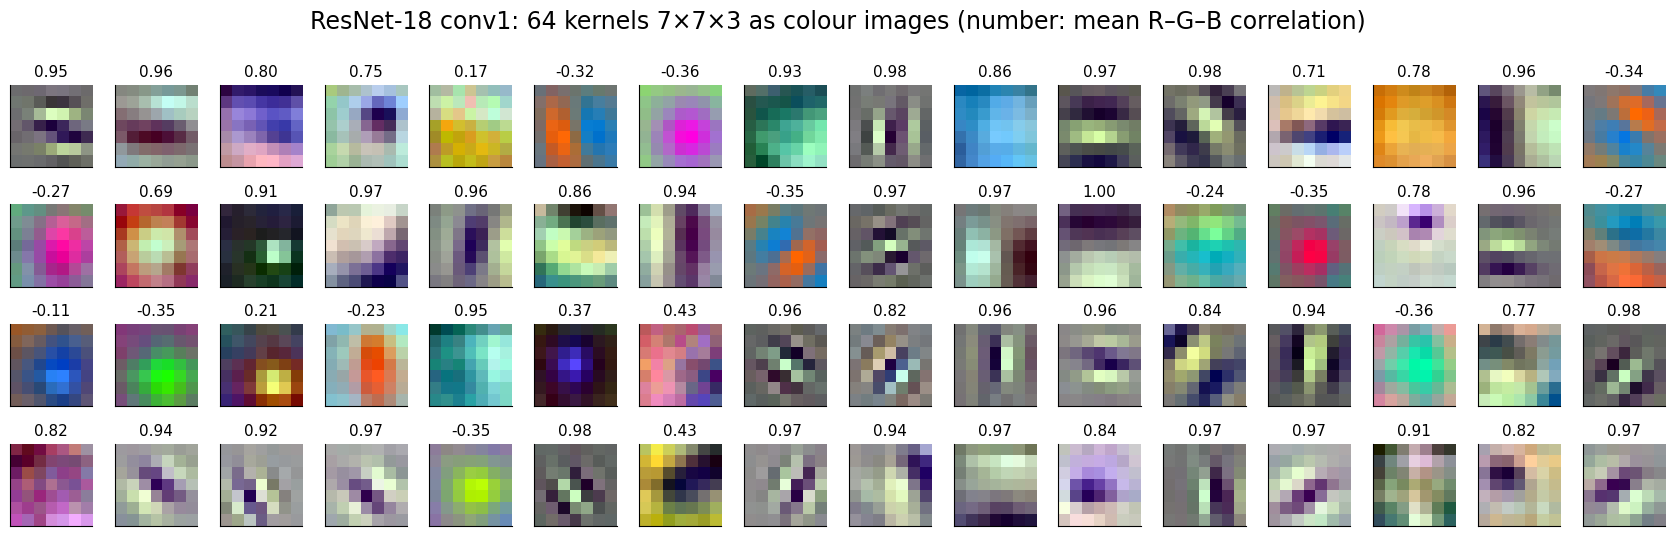

kernels with R-G-B correlation > 0.8: 40, < 0.3: 15 of 64


In [28]:
def normalise01(w):
    # rescale each kernel (first axis) separately to [0, 1]
    w = np.asarray(w, dtype=np.float64)
    lo = w.reshape(len(w), -1).min(1).reshape(-1, *[1] * (w.ndim - 1)); hi = w.reshape(len(w), -1).max(1).reshape(-1, *[1] * (w.ndim - 1))
    return (w - lo) / (hi - lo + 1e-12)

K1 = np.asarray(jresnet.conv1.kernel[...]).transpose(3, 0, 1, 2)       # (7, 7, 3, 64) -> (64, 7, 7, 3) = (kernel, row, column, colour)
def colour_correlation(K):
    # mean pairwise correlation between the R, G, B slices of each kernel
    S = K.reshape(len(K), -1, 3)
    return np.array([np.mean([np.corrcoef(s[:, i], s[:, j])[0, 1] for i, j in [(0, 1), (0, 2), (1, 2)]]) for s in S])
rgb_corr = colour_correlation(K1)

fig, axes = plt.subplots(4, 16, figsize=(17, 5.6))
for o, a in enumerate(axes.ravel()):
    a.imshow(normalise01(K1)[o], interpolation="nearest"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{rgb_corr[o]:.2f}", fontsize=11)
fig.suptitle("ResNet-18 conv1: 64 kernels 7×7×3 as colour images (number: mean R–G–B correlation)")
plt.tight_layout(); plt.show()
print(f"kernels with R-G-B correlation > 0.8: {np.sum(rgb_corr > 0.8)}, < 0.3: {np.sum(rgb_corr < 0.3)} of 64")

The 64 first-layer kernels fall into two groups. Forty have a correlation above 0.8 between their colour slices: they respond to brightness patterns, and many are oriented edge and bar detectors at several angles, or detectors of fine texture. Fifteen have a correlation below 0.3: they are colour-opponent blobs and edges. These generic features are what makes ImageNet networks transferable; they resemble the receptive fields of simple cells in the primary visual cortex.

### ImageNet normalisation and 64-pixel inputs

`weights.transforms()` lists the preprocessing of the training: resize to 256 pixels, crop the central $224\times224$ pixels, scale to $[0,1]$, and standardise each channel as in equation (4) with the ImageNet means $(0.485, 0.456, 0.406)$ and standard deviations $(0.229, 0.224, 0.225)$. The function `blood_as_imagenet` keeps the standardisation, because the first layer and the batch-normalisation statistics expect it, but not the resizing: we use the $64\times64$ version of BloodMNIST directly. The network accepts any image size because its last step averages each of the 512 final feature maps over whatever spatial size it has (adaptive average pooling in PyTorch, a mean over the two spatial axes here), $2\times2$ for a $64\times64$ input instead of $7\times7$ for $224\times224$. The price is a change of scale: at 64 pixels a cell covers far fewer pixels than objects in ImageNet photographs did, the stem reduces it to $16\times16$ positions, and the last stage sees only four positions. Enlarging the images to 128 pixels reduces this mismatch at four times the cost.

Shapes: `uint8` $(N,64,64,3)$ → `float32` $(N,64,64,3)$. The unchanged network with its 1000 ImageNet outputs, applied to 200 test cells, shows what it makes of blood cells.

In [29]:
X64_sub, y64_sub = blood_as_imagenet(b64["train_images"][SUB[800]]), yb_tr[SUB[800]]
X64_te, y64_te = blood_as_imagenet(b64["test_images"]), yb_te
assert X64_sub.shape == (6400, 64, 64, 3) and X64_te.shape == (3421, 64, 64, 3)
print("ImageNet mean", IMNET_MEAN, "std", IMNET_STD)
print("blood cells (64 px):", X64_sub.shape, " test:", X64_te.shape)

top = predict(jresnet, X64_te[:200]).argmax(1)
names, counts = np.unique([weights.meta["categories"][i] for i in top], return_counts=True)
print("ImageNet classes predicted by the unchanged network for 200 blood cells:",
      ", ".join(f"{n} ({c})" for n, c in sorted(zip(names, counts), key=lambda t: -t[1])[:5]))

ImageNet mean [0.485 0.456 0.406] std [0.229 0.224 0.225]
blood cells (64 px): (6400, 64, 64, 3)  test: (3421, 64, 64, 3)


ImageNet classes predicted by the unchanged network for 200 blood cells: golf ball (64), rubber eraser (19), face powder (14), remote control (14), honeycomb (13)


Without a new head the network answers in ImageNet terms: 64 of 200 blood cells are called "golf ball", followed by "rubber eraser" (19), "face powder" and "remote control" (14 each) and "honeycomb" (13), round or textured objects of similar appearance. The predictions are meaningless as labels, but they show that the features respond to roundness and fine texture, which is what distinguishes cell types.

### Stored outputs of the frozen layers

Since the frozen layers do not change and the images are not augmented, their output for a given image is the same in every training step, and it is wasteful to recompute it. We pass the 6400 labelled images of the largest subset and the 3421 test images through the frozen network once, in evaluation mode, and store two arrays: the output of `layer3`, shape $(N,4,4,256)$, needed for fine-tuning `layer4`, and the 512 pooled features after `layer4`, shape $(N,512)$, which are exactly the features $h$ of equation (1) that enter the output layer. Training on stored arrays is exact, not an approximation; the trained weights of both routes agree to rounding.

In [30]:
@nnx.jit
def trunk_and_features_fn(model, x):
    h3 = model.trunk(x)
    return h3, model.pooled(h3)

def trunk_and_features(model, X, size=None, keep_h3=True, batch=256):
    # frozen network in evaluation mode: layer3 outputs (N, s/16, s/16, 256) and the 512 pooled features (N, 512)
    model.eval(); H3, Fs = [], []
    for k in range(0, len(X), batch):
        x = jnp.asarray(X[k:k + batch])
        if size is not None: x = jax.image.resize(x, (len(x), size, size, 3), method="bilinear")
        h3, f = trunk_and_features_fn(model, x)
        Fs.append(np.asarray(f))
        if keep_h3: H3.append(np.asarray(h3))
    return (np.concatenate(H3) if keep_h3 else None), np.concatenate(Fs)

t0 = time.time(); H3_sub, F_sub = trunk_and_features(jresnet, X64_sub); T_EXTRACT_SUB = time.time() - t0
t0 = time.time(); H3_te, F_te = trunk_and_features(jresnet, X64_te); T_EXTRACT_TE = time.time() - t0
assert H3_sub.shape == (6400, 4, 4, 256) and F_sub.shape == (6400, 512)
print(f"stored: layer3 outputs {H3_sub.shape}, features {F_sub.shape}")
print(f"time: {T_EXTRACT_SUB:.1f} s for {len(X64_sub)} training images, {T_EXTRACT_TE:.1f} s for {len(X64_te)} test images"
      f" ({1000 * (T_EXTRACT_SUB + T_EXTRACT_TE) / (len(X64_sub) + len(X64_te)):.1f} ms per image)")

@nnx.jit
def top_logits(model, h3):
    # the end of the network: layer4, average pooling, fc
    return model.fc(model.pooled(h3))

def loss_top(model, h3, y):
    return optax.softmax_cross_entropy_with_integer_labels(top_logits(model, h3), y).mean()

stored: layer3 outputs (6400, 4, 4, 256), features (6400, 512)
time: 43.7 s for 6400 training images, 26.2 s for 3421 test images (7.1 ms per image)


### New head on the frozen network

The new output layer replaces the old one as an attribute, `model.fc = nnx.Linear(512, 8, rngs=...)`. The filter `FC = nnx.All(nnx.Param, nnx.PathContains("fc"))` selects its parameters, and both the gradient (`nnx.DiffState`) and the optimiser (`wrt=FC`) are restricted to it; the whole network stays in evaluation mode, so batch normalisation uses its ImageNet running statistics. Trained through the whole network, every step repeats the forward pass of 11 million frozen parameters for 64 images; trained on the stored features, a step costs a $64\times512$ by $512\times8$ matrix product, and `model.fc` can be passed to the optimiser on its own, because it is a module that shares its variables with `model`. Two copies trained for 50 steps with the same mini-batches, one through the full network and one on the stored features, and compares the resulting weights and the times.

In [31]:
FC = nnx.All(nnx.Param, nnx.PathContains("fc"))                         # the new output layer
NOT_FC = nnx.All(nnx.Any(nnx.Param, nnx.BatchStat), nnx.Not(nnx.PathContains("fc")))   # everything that stays frozen
step_fc = make_step(FC)

def resnet_new_head(seed=0):
    # a copy of the converted network with a new 512 -> 8 output layer
    m = nnx.clone(jresnet)
    m.fc = nnx.Linear(512, len(BLOOD_TYPES), rngs=nnx.Rngs(seed))
    return m

def frozen_part(m):
    return jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(m, NOT_FC)))

n, S_DEMO = 10, 50
m_full, m_cached = resnet_new_head(), resnet_new_head()
print(f"trainable: {sum(x.size for x in jax.tree.leaves(nnx.state(m_full, FC)))} of {count_params(m_full)} parameters")
before = frozen_part(m_full)
m_full.eval()                                                            # whole network in evaluation mode
t_full, _ = train_steps(m_full, nnx.Optimizer(m_full, optax.adam(1e-3), wrt=FC), step_fc, X64_sub[POS[n]], y64_sub[POS[n]], S_DEMO)
t_cached, _ = train_steps(m_cached.fc, nnx.Optimizer(m_cached.fc, optax.adam(1e-3), wrt=nnx.Param), step_all, F_sub[POS[n]], y64_sub[POS[n]], S_DEMO)
assert same_tree(before, frozen_part(m_full)), "the frozen network changed"
dw = np.abs(np.asarray(m_full.fc.kernel[...]) - np.asarray(m_cached.fc.kernel[...])).max()
assert dw < 1e-4 and np.allclose(m_full.fc.bias[...], m_cached.fc.bias[...], atol=1e-4)
print(f"{S_DEMO} steps through the whole frozen network: {t_full:.1f} s; on the stored features: {t_cached:.2f} s;"
      f" largest difference of the trained fc weights {dw:.1e}")
print(f"frozen part unchanged, checksum {checksum(before):.4f}")

trainable: 4104 of 11180616 parameters


50 steps through the whole frozen network: 25.5 s; on the stored features: 0.38 s; largest difference of the trained fc weights 0.0e+00
frozen part unchanged, checksum 169747.5759


The surgery on ResNet-18 removes the output layer for the 1000 ImageNet classes, with 513 000 parameters, and puts in its place a dense layer with 8 outputs and 4104 parameters; everything else is frozen.

pretrained ResNet-18 before the surgery (every parameter selected)
layer                   parameters  status
bn1                            128  trained
conv1                        9,408  trained
fc                         513,000  trained
layer1                     147,968  trained
layer2                     525,568  trained
layer3                   2,099,712  trained
layer4                   8,393,728  trained
trainable               11,689,512
frozen                           0

after replacing fc: filter FC selects the trained parameters
layer                   parameters  status
bn1                            128  frozen
conv1                        9,408  frozen
fc                           4,104  trained
layer1                     147,968  frozen
layer2                     525,568  frozen
layer3                   2,099,712  frozen
layer4                   8,393,728  frozen
trainable                    4,104
frozen                  11,176,512

per stage, after the surgery (64×6

saved results/Lab_014b_arch_resnet18_frozen.png


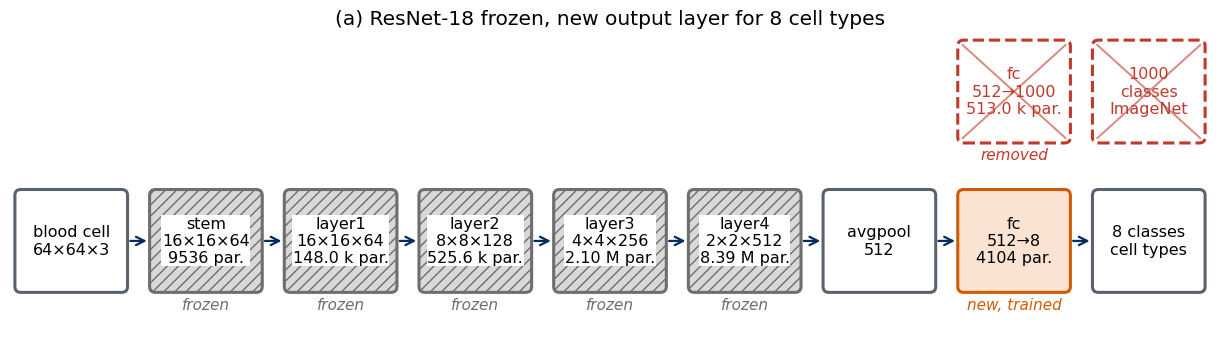

In [32]:
param_table(jresnet, nnx.Param, "pretrained ResNet-18 before the surgery (every parameter selected)")
param_table(m_full, FC, "after replacing fc: filter FC selects the trained parameters")
RESNET_STAGES = [(s, SH[64][s], mods) for s, mods in STAGE_MODS] + [("fc", fmt_shape((m_full.fc.out_features,)), ["fc"])]
stage_table(m_full, FC, RESNET_STAGES, "per stage, after the surgery (64×64 input)")

def new_fc_boxes(model, tag=None):
    return [dict(name="avgpool", detail=SH[64]["avgpool"], status="data"), fc_box(model, "new", tag),
            dict(name=f"{model.fc.out_features} classes", detail="cell types", status="data")]

total = draw_blocks([dict(name="blood cell", detail="64×64×3", status="data")] + resnet_blocks(m_full, lambda s: "frozen", lambda s: "frozen")
                    + new_fc_boxes(m_full) + [fc_box(jresnet, "removed", "removed", row=1, at=7),
                                              dict(name=f"{jresnet.fc.out_features}\nclasses", detail="ImageNet", status="removed", row=1, at=8, tag="")],
                    "(a) ResNet-18 frozen, new output layer for 8 cell types", os.path.join(RESULTS, "Lab_014b_arch_resnet18_frozen.png"))
assert total == count_params(m_full)

In [33]:
EPOCHS_HEAD, MIN_STEPS_HEAD = 50, 500
acc_B, time_B, models_B = {}, {}, {}
for k in ["frozen", "layer4", "random", "logreg"]: acc_B[k], time_B[k] = [], []
for n in BUDGETS:
    S = n_steps(n, EPOCHS_HEAD, MIN_STEPS_HEAD)
    m = resnet_new_head()
    t, loss = train_steps(m.fc, nnx.Optimizer(m.fc, optax.adam(1e-3), wrt=nnx.Param), step_all, F_sub[POS[n]], y64_sub[POS[n]], S)
    t += T_EXTRACT_SUB * len(SUB[n]) / len(SUB[800])                       # plus the feature extraction of these images
    acc = accuracy(m.fc, F_te, y64_te)
    acc_B["frozen"].append(acc); time_B["frozen"].append(t); models_B[("frozen", n)] = m
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs), final training loss {loss:.3f}, test accuracy {100 * acc:.1f}%")
assert np.allclose(predict(m, X64_te[:64]), predict(m.fc, F_te[:64]), atol=1e-4)   # the full network gives the same logits
assert np.allclose(predict(m, X64_te[:64]), predict(m, H3_te[:64], fn=top_logits), atol=1e-4)

n =  10: 500 steps (400 epochs), final training loss 0.018, test accuracy 65.9%


n = 100: 625 steps (50 epochs), final training loss 0.172, test accuracy 79.1%


n = 800: 5000 steps (50 epochs), final training loss 0.182, test accuracy 85.6%


After the surgery only the new output layer is trained: 4104 parameters, against 11 176 512 frozen ones. With 50 epochs on the stored features it reaches 65.9%, 79.1% and 85.6% at 10, 100 and 800 cells per type, with final training losses between 0.02 and 0.18. The frozen ImageNet features are clearly useful: with only 10 cells per type they separate the eight classes far better than chance (12.5%), and the accuracy grows steadily with the number of labels.

The head is then trained on the stored features for 50 epochs, with a minimum of 500 steps, Adam with learning rate $10^{-3}$. The reported time includes the share of the feature extraction that belongs to the labelled images.

### Fine-tuning the last stage

Next we unfreeze `layer4`, the last residual stage (8.4 million parameters), and train it together with `fc`, starting from the models of the previous step, with learning rate $10^{-4}$ for 5 epochs and at least 200 steps. `layer4` is in training mode, so its batch normalisation uses mini-batch statistics, while everything before it stays frozen. Training runs on the stored `layer3` outputs through `layer4` → average pooling → `fc`, which is again exact.

For fine-tuning, `layer4` is unfrozen together with the new output layer, so that 8.4 million of the 11.2 million parameters are trained; the stem and the first three stages stay frozen.

fine-tuning (c): filter L4FC selects layer4 and fc, learning rate 1e-4
layer                   parameters  status
bn1                            128  frozen
conv1                        9,408  frozen
fc                           4,104  trained
layer1                     147,968  frozen
layer2                     525,568  frozen
layer3                   2,099,712  frozen
layer4                   8,393,728  trained
trainable                8,397,832
frozen                   2,782,784

per stage, fine-tuning (c) (64×64 input)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  yes
fc                         8       4,104  yes
total                         11,180,616
trainable                      8,397,832
frozen                         2,782,784



saved results/Lab_014b_arch_resnet18_finetune.png


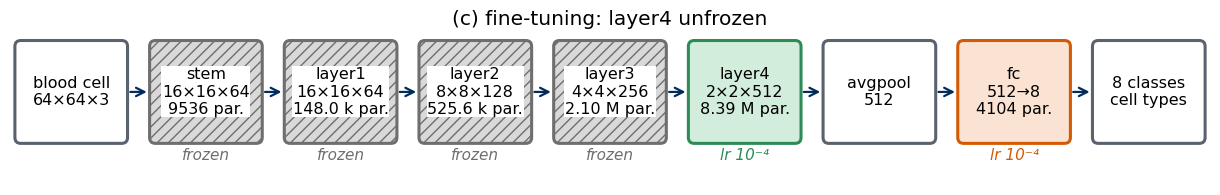

In [34]:
L4FC = nnx.All(nnx.Param, nnx.Any(nnx.PathContains("layer4"), nnx.PathContains("fc")))   # trained in (c): layer4 and fc
param_table(m_full, L4FC, "fine-tuning (c): filter L4FC selects layer4 and fc, learning rate 1e-4")
stage_table(m_full, L4FC, RESNET_STAGES, "per stage, fine-tuning (c) (64×64 input)")
total = draw_blocks([dict(name="blood cell", detail="64×64×3", status="data")]
                    + resnet_blocks(m_full, lambda s: "unfrozen" if s == "layer4" else "frozen", lambda s: "lr 10⁻⁴" if s == "layer4" else "frozen")
                    + new_fc_boxes(m_full, "lr 10⁻⁴"), "(c) fine-tuning: layer4 unfrozen", os.path.join(RESULTS, "Lab_014b_arch_resnet18_finetune.png"))
assert total == count_params(m_full)

In [35]:
EPOCHS_FT, MIN_STEPS_FT = 5, 200
L4FC = nnx.All(nnx.Param, nnx.Any(nnx.PathContains("layer4"), nnx.PathContains("fc")))   # trainable in (c)
step_top = make_step(L4FC, loss_top)
FROZEN_C = nnx.All(nnx.Any(nnx.Param, nnx.BatchStat), nnx.Not(nnx.Any(nnx.PathContains("layer4"), nnx.PathContains("fc"))))

for i, n in enumerate(BUDGETS):
    S = n_steps(n, EPOCHS_FT, MIN_STEPS_FT)
    mc = nnx.clone(models_B[("frozen", n)])                               # start from the trained new head
    before = jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(mc, FROZEN_C)))
    mc.eval()
    for block in mc.layer4: block.train()                                 # batch norm of layer4 uses mini-batch statistics
    t, loss = train_steps(mc, nnx.Optimizer(mc, optax.adam(1e-4), wrt=L4FC), step_top, H3_sub[POS[n]], y64_sub[POS[n]], S, seed=1)
    assert same_tree(before, jax.tree.map(np.array, nnx.to_pure_dict(nnx.state(mc, FROZEN_C))))
    acc = accuracy(mc, H3_te, y64_te, fn=top_logits)
    acc_B["layer4"].append(acc); time_B["layer4"].append(time_B["frozen"][i] + t); models_B[("layer4", n)] = mc
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs) in {t:5.1f} s, final training loss {loss:.3f},"
          f" test accuracy {100 * acc:.1f}% (new head alone: {100 * acc_B['frozen'][i]:.1f}%)")
assert np.allclose(predict(mc, X64_te[:64]), predict(mc, H3_te[:64], fn=top_logits), atol=1e-4)

n =  10: 200 steps (160 epochs) in 149.8 s, final training loss 0.000, test accuracy 61.7% (new head alone: 65.9%)


n = 100: 200 steps (16 epochs) in 308.0 s, final training loss 0.002, test accuracy 81.5% (new head alone: 79.1%)


n = 800: 500 steps (5 epochs) in 500.0 s, final training loss 0.036, test accuracy 90.0% (new head alone: 85.6%)


Fine-tuning `layer4` helps when there are enough labels and hurts when there are not. With 10 cells per type the training loss drops to zero and the test accuracy falls from 65.9% to 61.7%: 8.4 million parameters memorise 80 images. With 100 per type the accuracy rises from 79.1% to 81.5%, with 800 per type from 85.6% to 90.0%. Fine-tuning needs more labelled data than freezing.

### ResNet-18 from random initialisation

The fair reference for (a) and (c) is the same ResNet-18 with random weights, all 11.2 million parameters trained on the labelled cells, Adam with learning rate $10^{-3}$, batch normalisation in training mode. Every step runs the full forward and backward pass, so this is the most expensive run of the notebook; it gets 3 epochs with a minimum of 300 steps, which is far less training than such a network would normally receive.

In [36]:
EPOCHS_RAND, MIN_STEPS_RAND = 3, 300
for n in BUDGETS:
    S = n_steps(n, EPOCHS_RAND, MIN_STEPS_RAND)
    mr = ResNet18(len(BLOOD_TYPES), nnx.Rngs(0))                                   # random weights, 8 outputs
    mr.train()
    t, loss = train_steps(mr, nnx.Optimizer(mr, optax.adam(1e-3), wrt=nnx.Param), step_all, X64_sub[POS[n]], y64_sub[POS[n]], S)
    acc = accuracy(mr, X64_te, y64_te)
    acc_B["random"].append(acc); time_B["random"].append(t); models_B[("random", n)] = mr
    print(f"n = {n:3d}: {S} steps ({S * 64 / (8 * n):.0f} epochs) in {t:5.1f} s ({t / S:.2f} s per step),"
          f" final training loss {loss:.3f}, test accuracy {100 * acc:.1f}%")

n =  10: 300 steps (240 epochs) in 309.5 s (1.03 s per step), final training loss 0.000, test accuracy 62.9%


n = 100: 300 steps (24 epochs) in 326.0 s (1.09 s per step), final training loss 0.041, test accuracy 85.2%


n = 800: 300 steps (3 epochs) in 366.1 s (1.22 s per step), final training loss 0.207, test accuracy 80.8%


One step of the full ResNet-18 costs about 1.1 s here, far more than a step of the output layer on stored features. Trained from random initialisation for 300 steps, the network reaches 62.9%, 85.2% and 80.8%: slightly below the frozen ImageNet network with 10 cells per type, clearly above it with 100, and below it with 800, where 3 epochs are far too few for 11 million parameters (final training loss 0.21).

### Features and logistic regression

The fastest variant hands the stored features to `scikit-learn`: each feature is standardised to zero mean and unit variance on the training rows (`StandardScaler`), and a multinomial logistic regression with the default L2 penalty of `scikit-learn` is fitted by a quasi-Newton solver. Mathematically this is the frozen network with a linear head, as in (a), with a penalty on the weights and a different optimiser. The training time reported is the feature extraction of the labelled images plus the fit.

In [37]:
for n in BUDGETS:
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    t0 = time.time(); clf.fit(F_sub[POS[n]], yb_tr[SUB[n]]); t_fit = time.time() - t0
    acc = clf.score(F_te, yb_te)
    t_extract = T_EXTRACT_SUB * len(SUB[n]) / len(SUB[800])                # extraction time of the n-per-type images
    acc_B["logreg"].append(acc); time_B["logreg"].append(t_extract + t_fit); models_B[("logreg", n)] = clf
    print(f"n = {n:3d}: features {t_extract:5.1f} s + logistic regression {t_fit:5.2f} s, test accuracy {100 * acc:.1f}%")

n =  10: features   0.5 s + logistic regression  0.08 s, test accuracy 65.0%


n = 100: features   5.5 s + logistic regression  1.08 s, test accuracy 78.2%


n = 800: features  43.7 s + logistic regression  9.41 s, test accuracy 83.4%


### Images enlarged to 128 pixels

To measure the cost of the small input, we enlarge the images from 64 to 128 pixels by bilinear interpolation inside the extraction loop, extract the features of the 800 images of the 100-per-type subset and of the test set, and fit the same logistic regression. The computation per image grows roughly with the number of pixels, a factor of 4.

In [38]:
n = 100
t0 = time.time(); _, F128_sub = trunk_and_features(jresnet, X64_sub[POS[n]], size=128, keep_h3=False); t_sub = time.time() - t0
t0 = time.time(); _, F128_te = trunk_and_features(jresnet, X64_te, size=128, keep_h3=False); t_te = time.time() - t0
clf128 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(F128_sub, yb_tr[SUB[n]])
acc128 = clf128.score(F128_te, yb_te)
ms64 = 1000 * (T_EXTRACT_SUB + T_EXTRACT_TE) / (len(X64_sub) + len(X64_te)); ms128 = 1000 * (t_sub + t_te) / (len(F128_sub) + len(F128_te))
print(f"feature extraction: 64 px {ms64:.1f} ms per image, 128 px {ms128:.1f} ms per image (ratio {ms128 / ms64:.1f})")
print(f"logistic regression, {n} cells per type: 64 px {100 * acc_B['logreg'][1]:.1f}%, 128 px {100 * acc128:.1f}%")

feature extraction: 64 px 7.1 ms per image, 128 px 8.9 ms per image (ratio 1.2)
logistic regression, 100 cells per type: 64 px 78.2%, 128 px 82.7%


Enlarging the cells to 128 pixels raises the accuracy of logistic regression at 100 cells per type from 78.2% to 82.7%. The ImageNet features are tuned to objects that cover many pixels, and the larger input moves the cells closer to that scale. In this run the extraction at 128 pixels took only 1.2 times longer per image than at 64 pixels (8.9 against 7.1 ms).

### Comparison

The table and the figure collect the test accuracies of Section 3, with the training time of each method in brackets: for (a) and logistic regression the feature extraction of the labelled images plus the training, for (c) the time of (a) plus the fine-tuning, for (b) the full training. The small CIFAR-10 CNN architecture of Section 2, trained from random initialisation on the same cells at $32\times32$ pixels, is added as a second reference.

cells per type |          (a) frozen ResNet-18 + new head |             (c) (a) + fine-tuning layer4 | ResNet-18 features + logistic regression |     (b) ResNet-18, random initialisation | small CNN, random init.
            10 |                              65.9% (  1 s) |                              61.7% (151 s) |                              65.0% (  1 s) |                              62.9% (310 s) |       71.3% (419 s)
           100 |                              79.1% (  6 s) |                              81.5% (314 s) |                              78.2% (  7 s) |                              85.2% (326 s) |       81.2% ( 87 s)
           800 |                              85.6% ( 49 s) |                              90.0% (549 s) |                              83.4% ( 53 s) |                              80.8% (366 s) |       94.0% (733 s)


saved results/Lab_014b_transfer_resnet18_blood.png


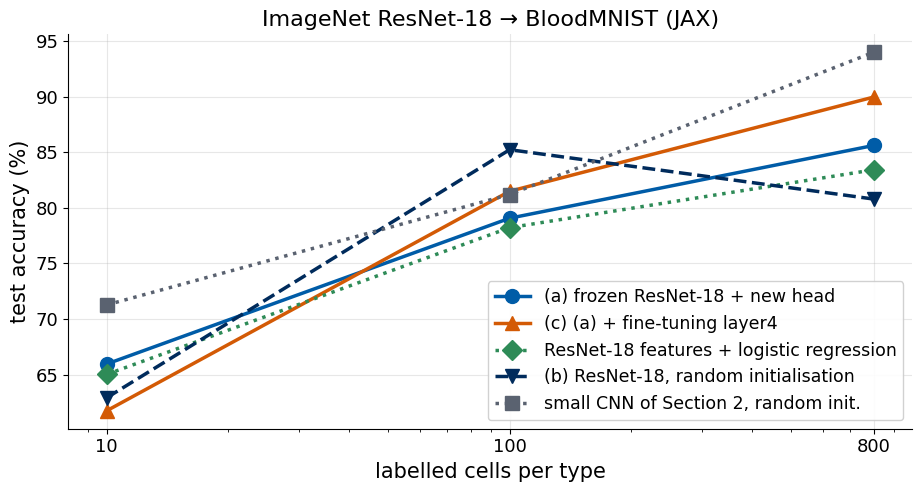

In [39]:
LABELS_B = {"frozen": "(a) frozen ResNet-18 + new head", "layer4": "(c) (a) + fine-tuning layer4",
            "logreg": "ResNet-18 features + logistic regression", "random": "(b) ResNet-18, random initialisation"}
print(f"{'cells per type':>14s} | " + " | ".join(f"{LABELS_B[m]:>40s}" for m in LABELS_B) + " | small CNN, random init.")
for i, n in enumerate(BUDGETS):
    print(f"{n:14d} | " + " | ".join(f"{100 * acc_B[m][i]:33.1f}% ({time_B[m][i]:3.0f} s)" for m in LABELS_B)
          + f" | {100 * acc_A['random'][i]:10.1f}% ({time_A['random'][i]:3.0f} s)")
plot_budget([(LABELS_B["frozen"], acc_B["frozen"], UJBlue, "o", "-"),
             (LABELS_B["layer4"], acc_B["layer4"], DSOrange, "^", "-"),
             (LABELS_B["logreg"], acc_B["logreg"], Green, "D", ":"),
             (LABELS_B["random"], acc_B["random"], UJNavy, "v", "--"),
             ("small CNN of Section 2, random init.", acc_A["random"], UJGray, "s", ":")],
            "ImageNet ResNet-18 → BloodMNIST (JAX)", os.path.join(RESULTS, "Lab_014b_transfer_resnet18_blood.png"))

Two findings stand out. First, logistic regression on frozen ResNet-18 features is the cheapest method, a few seconds including the feature extraction, and gives 65.0%, 78.2% and 83.4%, within about two points of the head trained with Adam (65.9%, 79.1%, 85.6%). For a new data set it is the right first experiment. Second, transfer from ImageNet does not beat training from random initialisation on this data set. The small CNN of Section 2, trained on the cells at $32\times32$ pixels, reaches 71.3%, 81.2% and 94.0% and is the best method at 10 and 800 cells per type; the randomly initialised ResNet-18 is best at 100 (85.2%). Fine-tuning `layer4` is the best transfer variant from 100 cells per type on (81.5%, 90.0%). BloodMNIST is homogeneous: centred cells, one staining protocol, one microscope, so a small network learns its few relevant features quickly.

(a) frozen ResNet-18 + new head            recall per type [0.79 0.8  0.73 0.63 0.84 0.77 0.87 0.89]; most frequent error immature granulocyte -> monocyte (85 of 579)


(c) (a) + fine-tuning layer4               recall per type [0.83 0.85 0.79 0.63 0.81 0.82 0.87 0.93]; most frequent error immature granulocyte -> monocyte (88 of 579)
ResNet-18 features + logistic regression   recall per type [0.82 0.81 0.77 0.56 0.79 0.72 0.86 0.92]; most frequent error immature granulocyte -> monocyte (119 of 579)


(b) ResNet-18, random initialisation       recall per type [0.88 0.95 0.78 0.58 0.87 0.75 0.96 0.99]; most frequent error immature granulocyte -> monocyte (102 of 579)


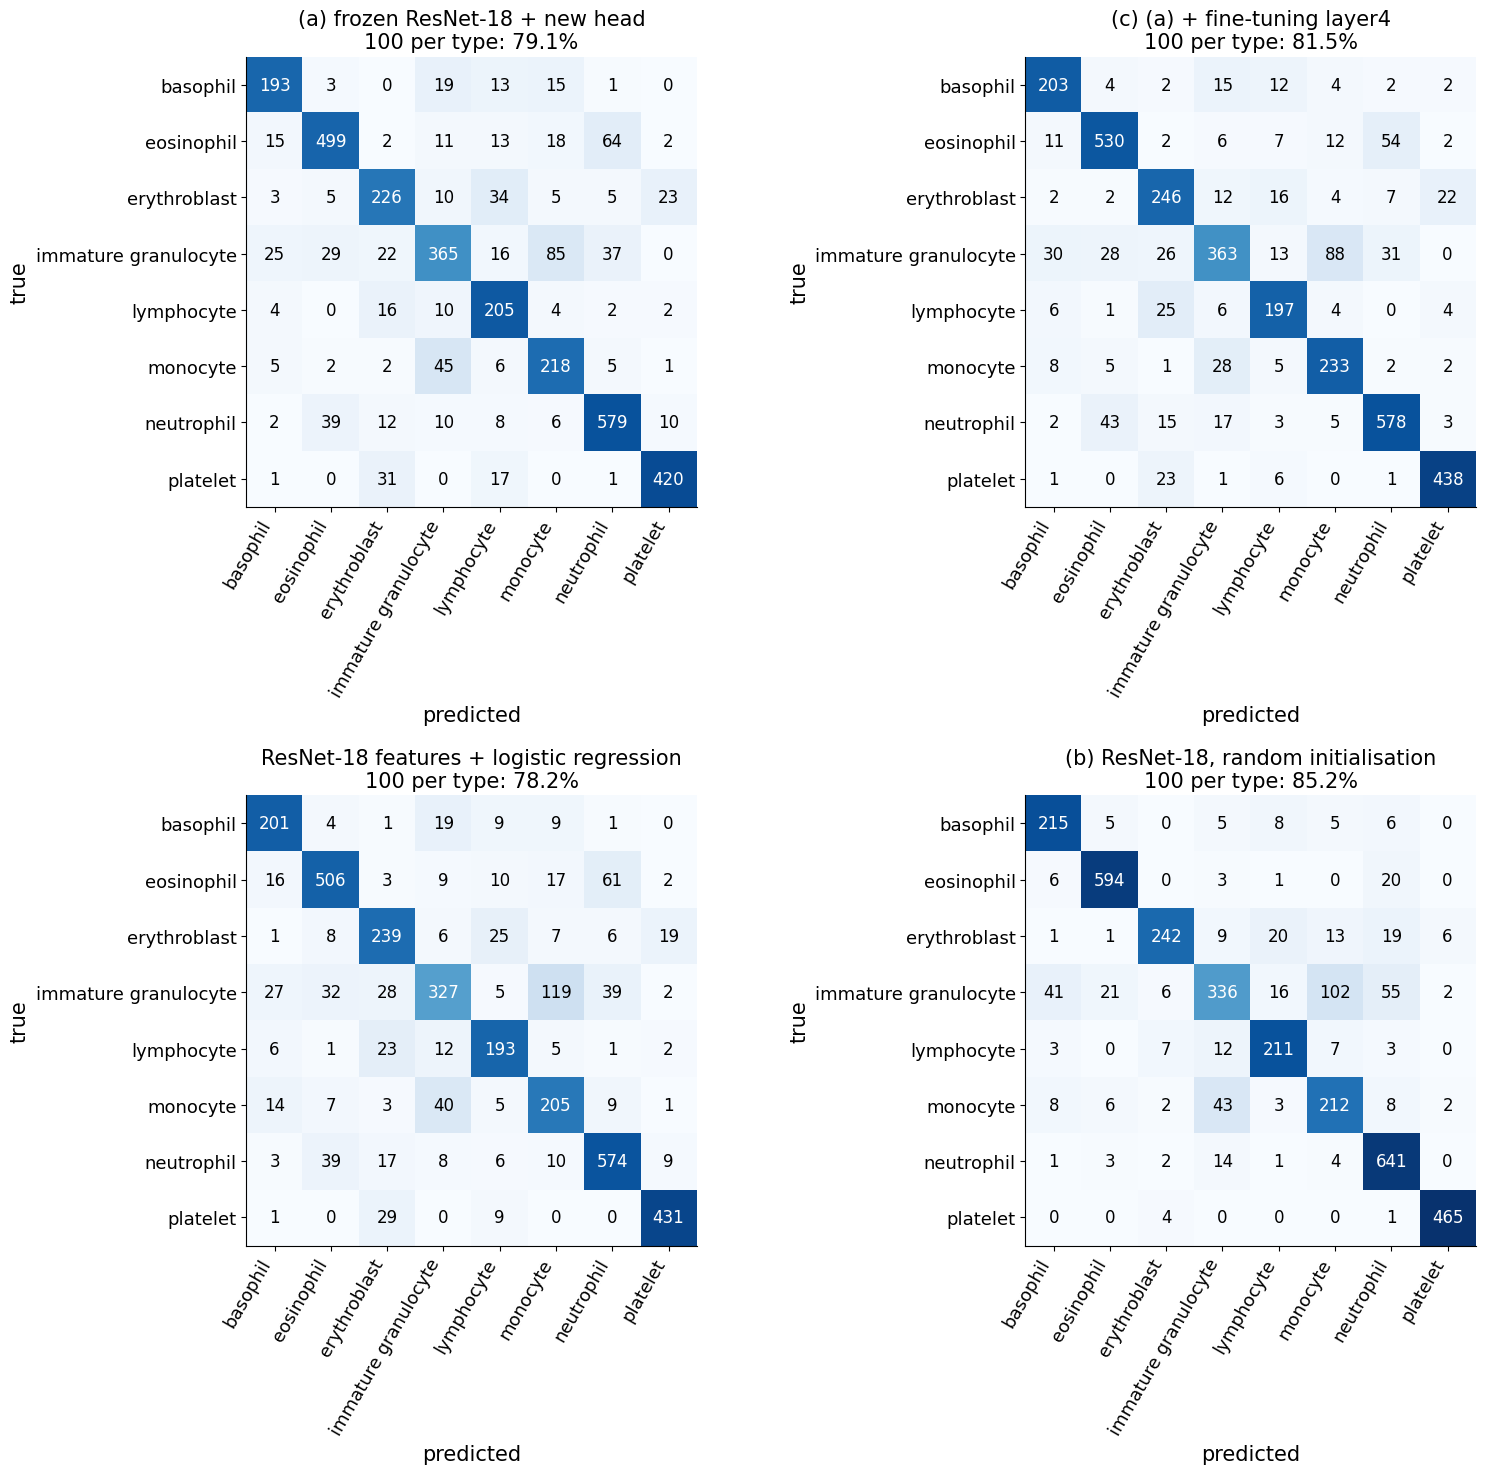

saved results/Lab_014b_resnet18_frozen_100_per_type.msgpack
saved results/Lab_014b_resnet18_layer4_100_per_type.msgpack
saved results/Lab_014b_resnet18_random_100_per_type.msgpack
saved results/Lab_014b_resnet18_features_logreg_100_per_type.npz


In [40]:
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for ax, m in zip(axes.ravel(), LABELS_B):
    if m == "logreg": pred = models_B[(m, 100)].predict(F_te)
    elif m == "layer4": pred = predict(models_B[(m, 100)], H3_te, fn=top_logits).argmax(1)
    else: pred = predict(models_B[(m, 100)], X64_te).argmax(1)
    cm = confusion_matrix(yb_te, pred)
    plot_confusion(ax, cm, BLOOD_TYPES, f"{LABELS_B[m]}\n100 per type: {100 * (pred == yb_te).mean():.1f}%")
    print(f"{LABELS_B[m]:42s} recall per type {np.round(np.diag(cm) / cm.sum(1), 2)}; most frequent error {most_confused(cm)}")
plt.tight_layout(); plt.show()
for m in ["frozen", "layer4", "random"]:
    print("saved", save(models_B[(m, 100)], os.path.join(RESULTS, f"Lab_014b_resnet18_{m}_100_per_type.msgpack")))
clf = models_B[("logreg", 100)]
path = os.path.join(RESULTS, "Lab_014b_resnet18_features_logreg_100_per_type.npz")
np.savez(path, coef=clf[-1].coef_, intercept=clf[-1].intercept_, mean=clf[0].mean_, scale=clf[0].scale_); print("saved", path)

All four ResNet-18 models make the same main error, immature granulocytes predicted as monocytes (85 to 119 of 579), as the CIFAR-10 models of Section 2 did. The random-initialisation network has the highest recall on neutrophils (0.96) and eosinophils (0.95); fine-tuning `layer4` gives the most even recall, between 0.63 and 0.93. The hard pair is the same for every network and every training regime, which points to the data (similar morphology, small images) rather than to the method.

## 4. A pretrained ResNet-18 on satellite images

On blood cells, neither our CIFAR-10 network nor the ImageNet ResNet-18 beat a small CNN trained from random initialisation. The same recipe is now applied to a target that resembles the source much more closely: small colour images of European landscapes taken from orbit, with ten classes defined by textures and colours (fields, forest, water, roads, houses) of the kind that fill ImageNet photographs.

### Satellite images (EuroSAT)

EuroSAT (P. Helber, B. Bischke, A. Dengel, D. Borth, *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing 12, 2217–2226 (2019), [doi:10.1109/JSTARS.2019.2918242](https://doi.org/10.1109/JSTARS.2019.2918242)) consists of 27 000 image patches from the Sentinel-2 satellites of the European Copernicus programme, covering 34 European countries. One sample is a $64\times64$ pixel patch; at the 10 m ground resolution of the visible bands it shows a square of 640 m by 640 m. The satellites record 13 spectral bands; the RGB version used here keeps the red, green and blue bands (Sentinel-2 bands B04, B03, B02) as an 8-bit colour JPEG image, three integers from 0 to 255 per pixel. The data are distributed under the MIT licence on [Zenodo](https://zenodo.org/records/7711810) and on the [authors' page](https://github.com/phelber/EuroSAT); the Sentinel data themselves are free under the Copernicus terms. The local file `data/EuroSAT.zip` is the RGB version; without it the notebook downloads `EuroSAT_RGB.zip` (95 MB) from Zenodo.

| class | images | what the patch shows |
|---|---|---|
| AnnualCrop | 3000 | arable fields sown every year |
| Forest | 3000 | closed tree cover |
| HerbaceousVegetation | 3000 | grassland and shrubs, not grazed |
| Highway | 2500 | a motorway or major road crossing the patch |
| Industrial | 2500 | industrial buildings and yards |
| Pasture | 2000 | grazed meadows |
| PermanentCrop | 2500 | orchards and vineyards |
| Residential | 3000 | houses and streets |
| River | 2500 | a river crossing the patch |
| SeaLake | 3000 | open water |

For each class we fix one random order of its images (seed 0). The first 200 images of every class form the test set, 2000 images in total, and the next 1000 form a pool from which the labelled training images are drawn: 10, 100 or 1000 per class. Only these 12 000 images are decoded.

In [41]:
EURO_GRID_PATH, BEAMER_FIGS = None, False      # Lab 014a saves the slide figures

import zipfile, io
from PIL import Image

EUROSAT_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"

def eurosat_zip():
    # the RGB archive: local copy first, otherwise the Zenodo record of the authors (95 MB)
    for name in ["EuroSAT.zip", "EuroSAT_RGB.zip"]:
        if os.path.exists(os.path.join(DATA, name)): return os.path.join(DATA, name)
    path = os.path.join(DATA, "EuroSAT_RGB.zip"); print("downloading EuroSAT RGB ...")
    urllib.request.urlretrieve(EUROSAT_URL, path)
    return path

zf = zipfile.ZipFile(eurosat_zip())
files = sorted(n for n in zf.namelist() if n.lower().endswith(".jpg"))
EURO_CLASSES = sorted({n.split("/")[-2] for n in files})                     # class = name of the parent folder
by_class = [[n for n in files if n.split("/")[-2] == c] for c in EURO_CLASSES]
N_TEST_EU, N_POOL_EU = 200, 1000
r = np.random.default_rng(0)
order = [r.permutation(len(f)) for f in by_class]
te_files = [by_class[c][i] for c in range(10) for i in order[c][:N_TEST_EU]]
pool_files = [by_class[c][i] for c in range(10) for i in order[c][N_TEST_EU:N_TEST_EU + N_POOL_EU]]
read = lambda names: np.stack([np.asarray(Image.open(io.BytesIO(zf.read(n))).convert("RGB")) for n in names])
t0 = time.time()
Xe_te_raw, ye_te = read(te_files), np.repeat(np.arange(10), N_TEST_EU).astype(np.int32)        # (2000, 64, 64, 3) uint8
Xe_pool_raw, ye_pool = read(pool_files), np.repeat(np.arange(10), N_POOL_EU).astype(np.int32)  # (10000, 64, 64, 3) uint8
assert Xe_te_raw.shape == (2000, 64, 64, 3) and Xe_pool_raw.shape == (10000, 64, 64, 3)
print(f"{len(files)} images in the archive, decoded {len(te_files) + len(pool_files)} in {time.time() - t0:.1f} s")
print(f"{'class':22s} {'images':>7s}")
for c, f in zip(EURO_CLASSES, by_class): print(f"{c:22s} {len(f):7d}")

27000 images in the archive, decoded 12000 in 5.0 s
class                   images
AnnualCrop                3000
Forest                    3000
HerbaceousVegetation      3000
Highway                   2500
Industrial                2500
Pasture                   2000
PermanentCrop             2500
Residential               3000
River                     2500
SeaLake                   3000


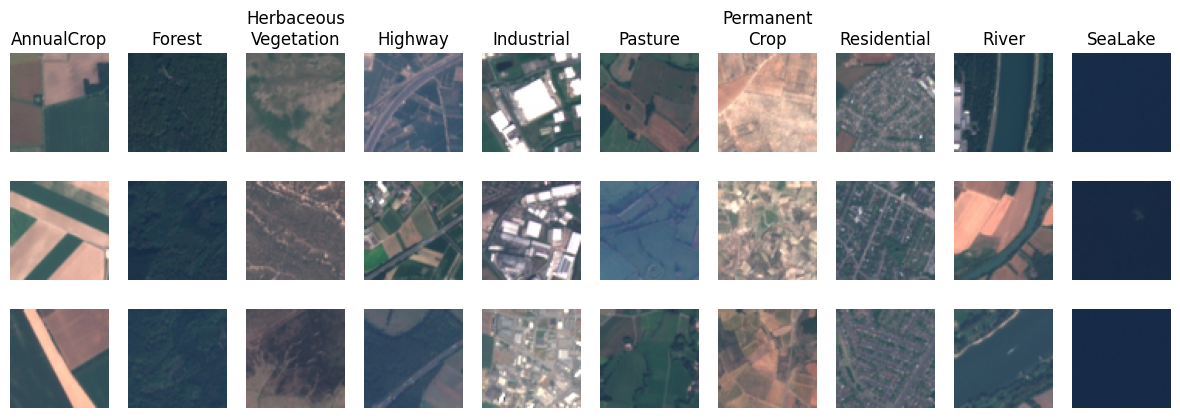

In [42]:
with plt.rc_context({"font.size": 13}):
    fig, axes = plt.subplots(3, 10, figsize=(12, 4.6))
    for c in range(10):
        for k in range(3):
            axes[k, c].imshow(Xe_pool_raw[c * N_POOL_EU + k]); axes[k, c].axis("off")
        axes[0, c].set_title({"HerbaceousVegetation": "Herbaceous\nVegetation", "PermanentCrop": "Permanent\nCrop"}.get(EURO_CLASSES[c], EURO_CLASSES[c]), fontsize=12)
    fig.tight_layout()
    if EURO_GRID_PATH: fig.savefig(EURO_GRID_PATH, dpi=150); print("saved", EURO_GRID_PATH)
    plt.show()

With 10 and 100 labelled images per class the result depends on which images happen to be labelled, so the cheap methods are repeated for three random draws (seeds 0, 1, 2) and reported as mean and standard deviation over the $S$ seeds,
$$\bar a=\frac1S\sum_{s=1}^{S}a_s,\qquad \sigma_a=\Big(\frac1{S-1}\sum_{s=1}^{S}(a_s-\bar a)^2\Big)^{1/2}, \tag{7}$$
where $a_s$ is the test accuracy for seed $s$. With 1000 per class the whole pool is labelled and there is one run.

In [43]:
BUDGETS_EU, SEEDS_EU = [10, 100, 1000], [0, 1, 2]
RAND_BUDGETS_EU = [10, 100]                     # randomly initialised ResNet-18: two budgets (run time on the CPU)

def euro_subset(n, seed):
    # positions in the pool of n labelled images per class (all 1000 when n = 1000)
    r = np.random.default_rng(100 + seed)
    return np.concatenate([c * N_POOL_EU + (np.arange(N_POOL_EU) if n == N_POOL_EU else r.choice(N_POOL_EU, n, replace=False))
                           for c in range(10)])

seeds_for = lambda n: SEEDS_EU if n < N_POOL_EU else [0]
assert all(np.array_equal(np.bincount(ye_pool[euro_subset(n, s)]), [n] * 10) for n in BUDGETS_EU for s in seeds_for(n))
Xe_pool, Xe_te = blood_as_imagenet(Xe_pool_raw), blood_as_imagenet(Xe_te_raw)    # the same ImageNet standardisation, equation (4)
print("EuroSAT pool", Xe_pool.shape, " test", Xe_te.shape)

EuroSAT pool (10000, 64, 64, 3)  test (2000, 64, 64, 3)


### Frozen ImageNet features and logistic regression

The frozen ResNet-18 turns every patch into 512 features, at the native 64 pixels and after bilinear enlargement to 128 pixels; the `layer3` outputs at 64 pixels are stored as well, for fine-tuning. A logistic regression on standardised features, as in Section 3, is then fitted for every budget and seed.

In [44]:
t0 = time.time(); H3e_pool, Fe_pool = trunk_and_features(jresnet, Xe_pool); H3e_te, Fe_te = trunk_and_features(jresnet, Xe_te)
t64 = time.time() - t0
t0 = time.time(); _, Fe_pool128 = trunk_and_features(jresnet, Xe_pool, size=128, keep_h3=False)
_, Fe_te128 = trunk_and_features(jresnet, Xe_te, size=128, keep_h3=False); t128 = time.time() - t0
n_img = len(Xe_pool) + len(Xe_te)
print(f"features of {n_img} images: 64 px {t64:.1f} s ({1000 * t64 / n_img:.1f} ms per image), 128 px {t128:.1f} s ({1000 * t128 / n_img:.1f} ms per image)")

ACC_EU = {}                                                                 # (method, n) -> list of test accuracies over seeds
TIME_EU = {}
def record(method, n, acc, t):
    ACC_EU.setdefault((method, n), []).append(acc); TIME_EU.setdefault((method, n), []).append(t)

LR_EU = {}
for n in BUDGETS_EU:
    for s in seeds_for(n):
        idx = euro_subset(n, s)
        for res, (Ftr, Fte) in {"64": (Fe_pool, Fe_te), "128": (Fe_pool128, Fe_te128)}.items():
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
            t0 = time.time(); clf.fit(Ftr[idx], ye_pool[idx]); t = time.time() - t0
            record(f"logreg{res}", n, clf.score(Fte, ye_te), t)
            if s == 0: LR_EU[(res, n)] = clf
    print(f"n = {n:4d} per class: logistic regression 64 px {100 * np.mean(ACC_EU[('logreg64', n)]):.1f}%,"
          f" 128 px {100 * np.mean(ACC_EU[('logreg128', n)]):.1f}%  ({len(seeds_for(n))} seed(s))")

features of 12000 images: 64 px 72.6 s (6.1 ms per image), 128 px 79.1 s (6.6 ms per image)


n =   10 per class: logistic regression 64 px 76.7%, 128 px 77.2%  (3 seed(s))


n =  100 per class: logistic regression 64 px 86.9%, 128 px 88.4%  (3 seed(s))


n = 1000 per class: logistic regression 64 px 89.1%, 128 px 91.2%  (1 seed(s))


The frozen ImageNet features separate the land-use classes well from very few labels: logistic regression reaches 76.7% with 10 images per class (mean over three seeds, standard deviation 1.2), 86.9% with 100 and 89.1% with 1000 at 64 pixels. Enlarging the patches to 128 pixels adds 0.5 to 2.1 points (77.2%, 88.4%, 91.2%). The step from 10 to 100 labels is worth ten points, the step from 100 to 1000 only two to three.

### New head and fine-tuning on EuroSAT

The surgery is the one of Section 3 with a new output layer of 10 classes instead of 8. The new layer is trained with Adam on the stored features of the 64-pixel patches (50 epochs, at least 500 steps); then `layer4` is unfrozen and trained together with it on the stored `layer3` outputs (5 epochs, at least 200 steps, learning rate $10^{-4}$), for seed 0. The diagrams and the stage table are read from the model as before.

per stage, frozen network with new output layer (64×64 input)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  no
fc                        10       5,130  yes
total                         11,181,642
trainable                          5,130
frozen                        11,176,512



saved results/Lab_014b_arch_eurosat_frozen.png


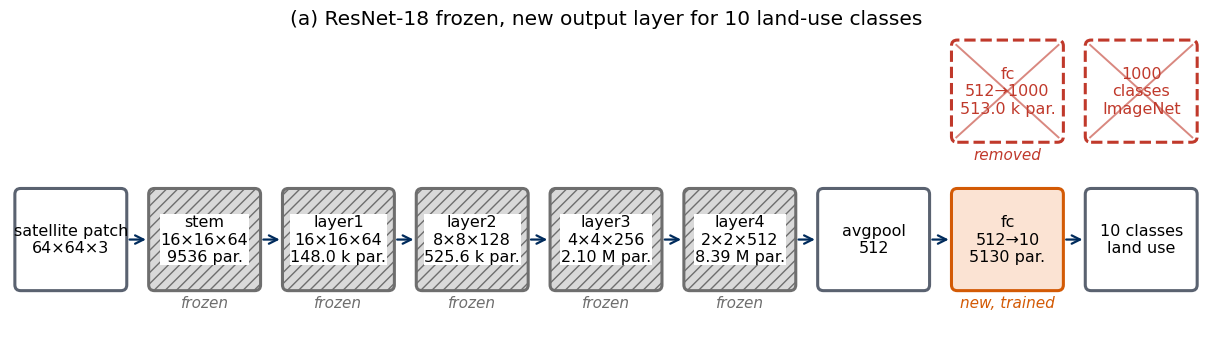

per stage, fine-tuning (c)
stage           output shape  parameters  trainable
stem                16×16×64       9,536  no
layer1              16×16×64     147,968  no
layer2               8×8×128     525,568  no
layer3               4×4×256   2,099,712  no
layer4               2×2×512   8,393,728  yes
fc                        10       5,130  yes
total                         11,181,642
trainable                      8,398,858
frozen                         2,782,784



saved results/Lab_014b_arch_eurosat_finetune.png


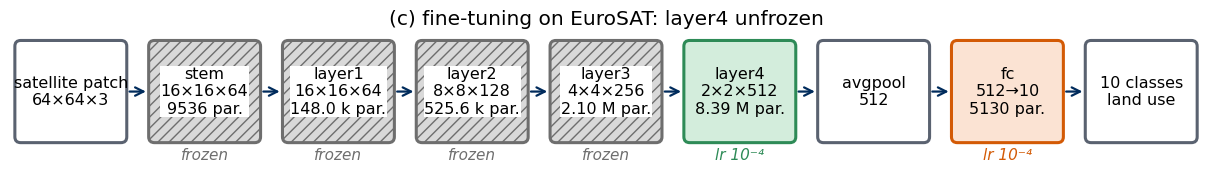

In [45]:
m_eu = nnx.clone(jresnet); m_eu.fc = nnx.Linear(512, len(EURO_CLASSES), rngs=nnx.Rngs(0))
EU_STAGES = [(s, SH[64][s], mods) for s, mods in STAGE_MODS] + [("fc", fmt_shape((m_eu.fc.out_features,)), ["fc"])]
stage_table(m_eu, FC, EU_STAGES, "per stage, frozen network with new output layer (64×64 input)")
euro_out = lambda m, tag=None: [dict(name="avgpool", detail=SH[64]["avgpool"], status="data"), fc_box(m, "new", tag),
                                dict(name=f"{m.fc.out_features} classes", detail="land use", status="data")]
total = draw_blocks([dict(name="satellite patch", detail="64×64×3", status="data")] + resnet_blocks(m_eu, lambda s: "frozen", lambda s: "frozen")
                    + euro_out(m_eu) + [fc_box(jresnet, "removed", "removed", row=1, at=7),
                                        dict(name=f"{jresnet.fc.out_features}\nclasses", detail="ImageNet", status="removed", row=1, at=8, tag="")],
                    "(a) ResNet-18 frozen, new output layer for 10 land-use classes", os.path.join(RESULTS, "Lab_014b_arch_eurosat_frozen.png"))
assert total == count_params(m_eu)
stage_table(m_eu, L4FC, EU_STAGES, "per stage, fine-tuning (c)")
total = draw_blocks([dict(name="satellite patch", detail="64×64×3", status="data")]
                    + resnet_blocks(m_eu, lambda s: "unfrozen" if s == "layer4" else "frozen", lambda s: "lr 10⁻⁴" if s == "layer4" else "frozen")
                    + euro_out(m_eu, "lr 10⁻⁴"), "(c) fine-tuning on EuroSAT: layer4 unfrozen", os.path.join(RESULTS, "Lab_014b_arch_eurosat_finetune.png"))
assert total == count_params(m_eu)

In [46]:
MODELS_EU = {}
for n in BUDGETS_EU:
    idx = euro_subset(n, 0)
    m = nnx.clone(m_eu)
    S = max(MIN_STEPS_HEAD, int(np.ceil(EPOCHS_HEAD * 10 * n / 64)))
    t_a, l_a = train_steps(m.fc, nnx.Optimizer(m.fc, optax.adam(1e-3), wrt=nnx.Param), step_all, Fe_pool[idx], ye_pool[idx], S)
    record("head", n, accuracy(m.fc, Fe_te, ye_te), t_a)
    S4 = max(MIN_STEPS_FT, int(np.ceil(EPOCHS_FT * 10 * n / 64)))
    m.eval()
    for block in m.layer4: block.train()
    t_c, l_c = train_steps(m, nnx.Optimizer(m, optax.adam(1e-4), wrt=L4FC), step_top, H3e_pool[idx], ye_pool[idx], S4, seed=1)
    record("layer4", n, accuracy(m, H3e_te, ye_te, fn=top_logits), t_a + t_c); MODELS_EU[("layer4", n)] = m
    print(f"n = {n:4d}: new head {S} steps, loss {l_a:.3f}, test {100 * ACC_EU[('head', n)][0]:.1f}% | "
          f"layer4 {S4} steps in {t_c:.0f} s, loss {l_c:.3f}, test {100 * ACC_EU[('layer4', n)][0]:.1f}%")

n =   10: new head 500 steps, loss 0.008, test 74.2% | layer4 200 steps in 149 s, loss 0.000, test 71.0%


n =  100: new head 782 steps, loss 0.045, test 86.4% | layer4 200 steps in 143 s, loss 0.002, test 86.4%


n = 1000: new head 7813 steps, loss 0.066, test 90.0% | layer4 782 steps in 2409 s, loss 0.029, test 92.5%


The new output layer trained with Adam on the stored features gives 74.2%, 86.4% and 90.0%, close to logistic regression on the same features, as it should for the same model. Fine-tuning `layer4` again depends on the number of labels: with 10 per class it overfits (training loss 0.000) and falls to 71.0%, with 100 it is level (86.4%), and with 1000 per class it is the best method on this data set, 92.5%.

### References trained from random initialisation

Two networks start from random weights: the same ResNet-18, trained on the 64-pixel patches with Adam (learning rate $10^{-3}$, 3 epochs and at least 300 steps, seed 0; only for 10 and 100 per class, because a full training step of ResNet-18 in JAX on the CPU is too slow for the third budget within the run time of the notebook), and the small CNN architecture of Section 2 with new layers for 10 classes, trained on the patches reduced to $32\times32$ pixels by averaging $2\times2$ blocks and standardised with the means and standard deviations of the pool (twice 20 epochs and at least 600 steps, three seeds for 10 and 100 per class).

In [47]:
for n in RAND_BUDGETS_EU:
    idx = euro_subset(n, 0)
    S = max(MIN_STEPS_RAND, int(np.ceil(EPOCHS_RAND * 10 * n / 64)))
    mr = ResNet18(10, nnx.Rngs(0)); mr.train()
    t, loss = train_steps(mr, nnx.Optimizer(mr, optax.adam(1e-3), wrt=nnx.Param), step_all, Xe_pool[idx], ye_pool[idx], S)
    record("resnet_random", n, accuracy(mr, Xe_te, ye_te), t); MODELS_EU[("resnet_random", n)] = mr
    print(f"n = {n:4d}: ResNet-18 random init., {S} steps in {t:.0f} s, loss {loss:.3f}, test {100 * ACC_EU[('resnet_random', n)][0]:.1f}%")

to32 = lambda X: (X.astype(np.float32) / 255).reshape(len(X), 32, 2, 32, 2, 3).mean(axis=(2, 4))   # average of 2x2 blocks
X32_pool, X32_te = to32(Xe_pool_raw), to32(Xe_te_raw)                                               # (N, 32, 32, 3)
mu32, sd32 = X32_pool.mean((0, 1, 2)), X32_pool.std((0, 1, 2))
X32_pool, X32_te = ((X32_pool - mu32) / sd32).astype(np.float32), ((X32_te - mu32) / sd32).astype(np.float32)
for n in BUDGETS_EU:
    for s in seeds_for(n):
        idx = euro_subset(n, s)
        S = 2 * max(MIN_STEPS_A, int(np.ceil(EPOCHS_A * 10 * n / 64)))
        mc = TransferNet(CifarBody(True, nnx.Rngs(params=s, dropout=s + 1)), nnx.Rngs(params=s, dropout=s + 1), n_classes=10)
        mc.train()
        t, loss = train_steps(mc, nnx.Optimizer(mc, optax.adam(1e-3), wrt=nnx.Param), step_all, X32_pool[idx], ye_pool[idx], S, seed=s)
        record("small_cnn", n, accuracy(mc, X32_te, ye_te), t)
        if s == 0: MODELS_EU[("small_cnn", n)] = mc
    print(f"n = {n:4d}: small CNN random init., {S} steps, test {100 * np.mean(ACC_EU[('small_cnn', n)]):.1f}%"
          f" ± {100 * np.std(ACC_EU[('small_cnn', n)], ddof=1) if len(ACC_EU[('small_cnn', n)]) > 1 else 0:.1f}")

n =   10: ResNet-18 random init., 300 steps in 1354 s, loss 0.049, test 46.4%


n =  100: ResNet-18 random init., 300 steps in 2052 s, loss 0.136, test 68.7%


n =   10: small CNN random init., 600 steps, test 55.3% ± 1.8


n =  100: small CNN random init., 626 steps, test 77.1% ± 1.1


n = 1000: small CNN random init., 6250 steps, test 89.7% ± 0.0


Without pretrained weights the picture changes completely. ResNet-18 from random initialisation reaches only 46.4% and 68.7% with 10 and 100 images per class, after 300 steps that take 23 and 34 minutes on the CPU; the budget of 1000 images per class is left out, because a full training step of ResNet-18 in JAX on the CPU is too slow for it. The small CNN does better, 55.3 ± 1.8%, 77.1 ± 1.1% and 89.7%, but needs about 1000 labelled images per class to come close to the frozen features, which reach 77% with 10.

### Comparison on EuroSAT

The table lists the mean test accuracy over the seeds of equation (7), with the standard deviation where there are three seeds, and the training time of the first seed (for logistic regression the fit only; the features are extracted once for all methods).

method                                                  10               100              1000
features 64 px + logistic regression       76.7 ± 1.2 (  0 s)   86.9 ± 0.6 (  1 s)   89.1 ± 0.0 (  8 s)
features 128 px + logistic regression      77.2 ± 1.4 (  0 s)   88.4 ± 0.7 (  1 s)   91.2 ± 0.0 (  5 s)
(a) frozen ResNet-18 + new fc              74.2 ± 0.0 (  1 s)   86.4 ± 0.0 (  1 s)   90.0 ± 0.0 (  8 s)
(c) (a) + fine-tuning layer4               71.0 ± 0.0 (150 s)   86.4 ± 0.0 (144 s)   92.5 ± 0.0 (2418 s)
(b) ResNet-18, random initialisation       46.4 ± 0.0 (1354 s)   68.7 ± 0.0 (2052 s)    nan ± 0.0 (nan s)
small CNN, random initialisation           55.3 ± 1.8 (212 s)   77.1 ± 1.1 (272 s)   89.7 ± 0.0 (2494 s)


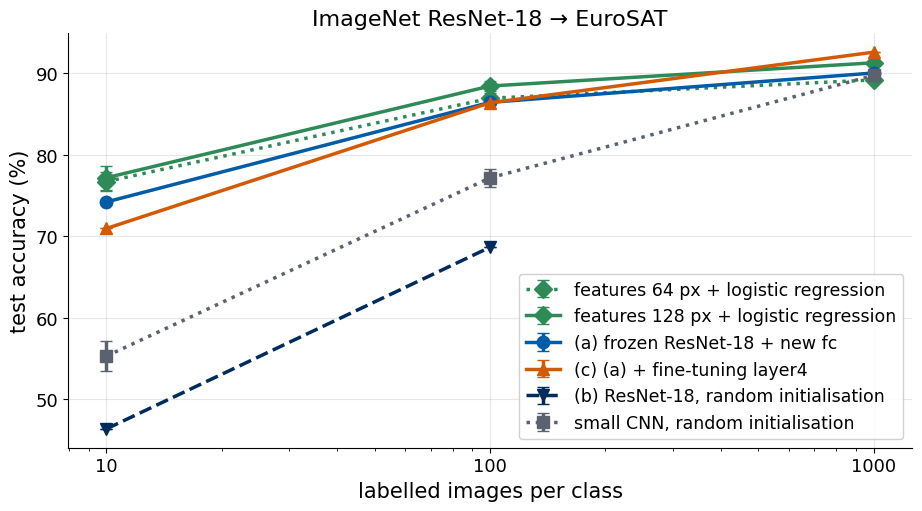

In [48]:
LABELS_EU = {"logreg64": "features 64 px + logistic regression", "logreg128": "features 128 px + logistic regression",
             "head": "(a) frozen ResNet-18 + new fc", "layer4": "(c) (a) + fine-tuning layer4",
             "resnet_random": "(b) ResNet-18, random initialisation", "small_cnn": "small CNN, random initialisation"}
def mean_std(m, n):
    # mean and standard deviation over seeds, equation (7); NaN when the run was not done
    if (m, n) not in ACC_EU: return np.nan, 0.0
    a = 100 * np.array(ACC_EU[(m, n)]); return a.mean(), (a.std(ddof=1) if len(a) > 1 else 0.0)
print(f"{'method':40s} " + " ".join(f"{n:>17d}" for n in BUDGETS_EU))
for m, lab in LABELS_EU.items():
    print(f"{lab:40s} " + " ".join(f"{mean_std(m, n)[0]:6.1f} ± {mean_std(m, n)[1]:3.1f} ({TIME_EU.get((m, n), [np.nan])[0]:3.0f} s)" for n in BUDGETS_EU))

STY = {"logreg64": (Green, "D", ":"), "logreg128": (Green, "D", "-"), "head": (UJBlue, "o", "-"), "layer4": (DSOrange, "^", "-"),
       "resnet_random": (UJNavy, "v", "--"), "small_cnn": (UJGray, "s", ":")}
def budget_panel(ax, budgets, curves, title):
    # curves: list of (label, means, stds, (colour, marker, linestyle))
    for lab, mu, sd, (c, mk, ls) in curves:
        ax.errorbar(budgets, mu, yerr=sd, marker=mk, ls=ls, color=c, lw=2.5, ms=9, capsize=4, label=lab)
    ax.set_xscale("log"); ax.set_xticks(budgets); ax.set_xticklabels([str(b) for b in budgets])
    ax.set_ylabel("test accuracy (%)"); ax.set_title(title); ax.grid(alpha=0.3)

with plt.rc_context({"font.size": 16, "legend.fontsize": 12.5}):
    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    budget_panel(ax, BUDGETS_EU, [(LABELS_EU[m], [mean_std(m, n)[0] for n in BUDGETS_EU], [mean_std(m, n)[1] for n in BUDGETS_EU], STY[m])
                                  for m in LABELS_EU], "ImageNet ResNet-18 → EuroSAT")
    ax.set_xlabel("labelled images per class"); ax.legend(loc="lower right", framealpha=0.9)
    fig.tight_layout()
    if BEAMER_FIGS: fig.savefig(os.path.join(FIGS, "transfer_partC_eurosat.png"), dpi=200); print("saved", os.path.join(FIGS, "transfer_partC_eurosat.png"))
    plt.show()

On EuroSAT, transfer learning pays off clearly. With 10 labelled images per class, frozen ImageNet features with logistic regression (76.7%, or 77.2% at 128 pixels) beat the small CNN trained from random initialisation by 22 points and the randomly initialised ResNet-18 by 31; with 100 per class the gap to the small CNN is still 10 to 11 points (86.9–88.4% against 77.1%). With 1000 per class the small CNN (89.7%) comes within two points of the frozen features (89.1–91.2%), and only fine-tuning `layer4` stays ahead (92.5%). The cheapest method, a logistic regression fitted in about a second on features extracted once, is also the best one at small label budgets. The entry for the randomly initialised ResNet-18 at 1000 per class is empty because that run was skipped.

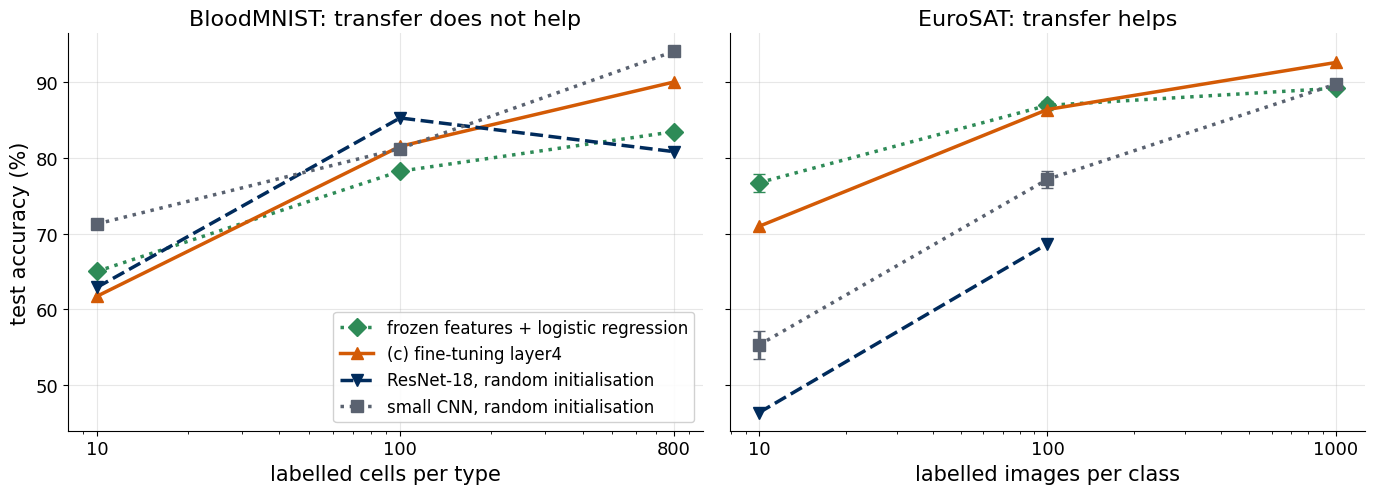

In [49]:
with plt.rc_context({"font.size": 15, "legend.fontsize": 12}):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
    budget_panel(axes[0], BUDGETS, [("frozen features + logistic regression", 100 * np.array(acc_B["logreg"]), None, STY["logreg64"]),
                                    ("(c) fine-tuning layer4", 100 * np.array(acc_B["layer4"]), None, STY["layer4"]),
                                    ("ResNet-18, random initialisation", 100 * np.array(acc_B["random"]), None, STY["resnet_random"]),
                                    ("small CNN, random initialisation", 100 * np.array(acc_A["random"]), None, STY["small_cnn"])],
                 "BloodMNIST: transfer does not help")
    budget_panel(axes[1], BUDGETS_EU, [("frozen features + logistic regression", [mean_std("logreg64", n)[0] for n in BUDGETS_EU],
                                        [mean_std("logreg64", n)[1] for n in BUDGETS_EU], STY["logreg64"]),
                                       ("(c) fine-tuning layer4", [mean_std("layer4", n)[0] for n in BUDGETS_EU], None, STY["layer4"]),
                                       ("ResNet-18, random initialisation", [mean_std("resnet_random", n)[0] for n in BUDGETS_EU], None, STY["resnet_random"]),
                                       ("small CNN, random initialisation", [mean_std("small_cnn", n)[0] for n in BUDGETS_EU],
                                        [mean_std("small_cnn", n)[1] for n in BUDGETS_EU], STY["small_cnn"])],
                 "EuroSAT: transfer helps")
    axes[0].set_xlabel("labelled cells per type"); axes[1].set_xlabel("labelled images per class"); axes[1].set_ylabel("")
    axes[0].legend(loc="lower right", framealpha=0.9)
    fig.tight_layout()
    if BEAMER_FIGS: fig.savefig(os.path.join(FIGS, "transfer_blood_vs_eurosat.png"), dpi=200); print("saved", os.path.join(FIGS, "transfer_blood_vs_eurosat.png"))
    plt.show()

The two panels show the same network with the same recipe on two targets, and opposite conclusions. Three differences between the targets explain them. The first is the distance between source and target images: EuroSAT patches are natural-colour photographs of fields, forest, water, roads and roofs, the textures and colours that ImageNet photographs are full of, whereas blood smears are stained cells with colour statistics far from ImageNet (the unchanged network calls most cells "golf ball"). The second is the variability of the target: BloodMNIST cells are centred, of similar size, recorded with one microscope and one staining protocol, so a small CNN learns the few features that separate the types from 80 labelled images (71.3%); EuroSAT patches vary in season, illumination, region and scale, and ten examples per class do not cover this variety unless the features already encode it. The third is the label budget: the advantage of pretrained features is largest at 10 and 100 labels per class and shrinks at 1000. Transfer from a large pretrained network is therefore the first experiment to try when labels are scarce and the target images look like natural photographs, and it should always be compared with a small network trained from random initialisation, which on homogeneous scientific images can win.

### Confusion matrices on EuroSAT

The four models trained on 100 images per class (seed 0): logistic regression on the 128-pixel features, the fine-tuned network, and the two references from random initialisation.

features 128 px + logistic regression    most frequent error River -> Highway (20 of 200)
(c) (a) + fine-tuning layer4             most frequent error River -> Highway (24 of 200)


(b) ResNet-18, random initialisation     most frequent error Highway -> River (51 of 200)
small CNN, random initialisation         most frequent error River -> Highway (36 of 200)


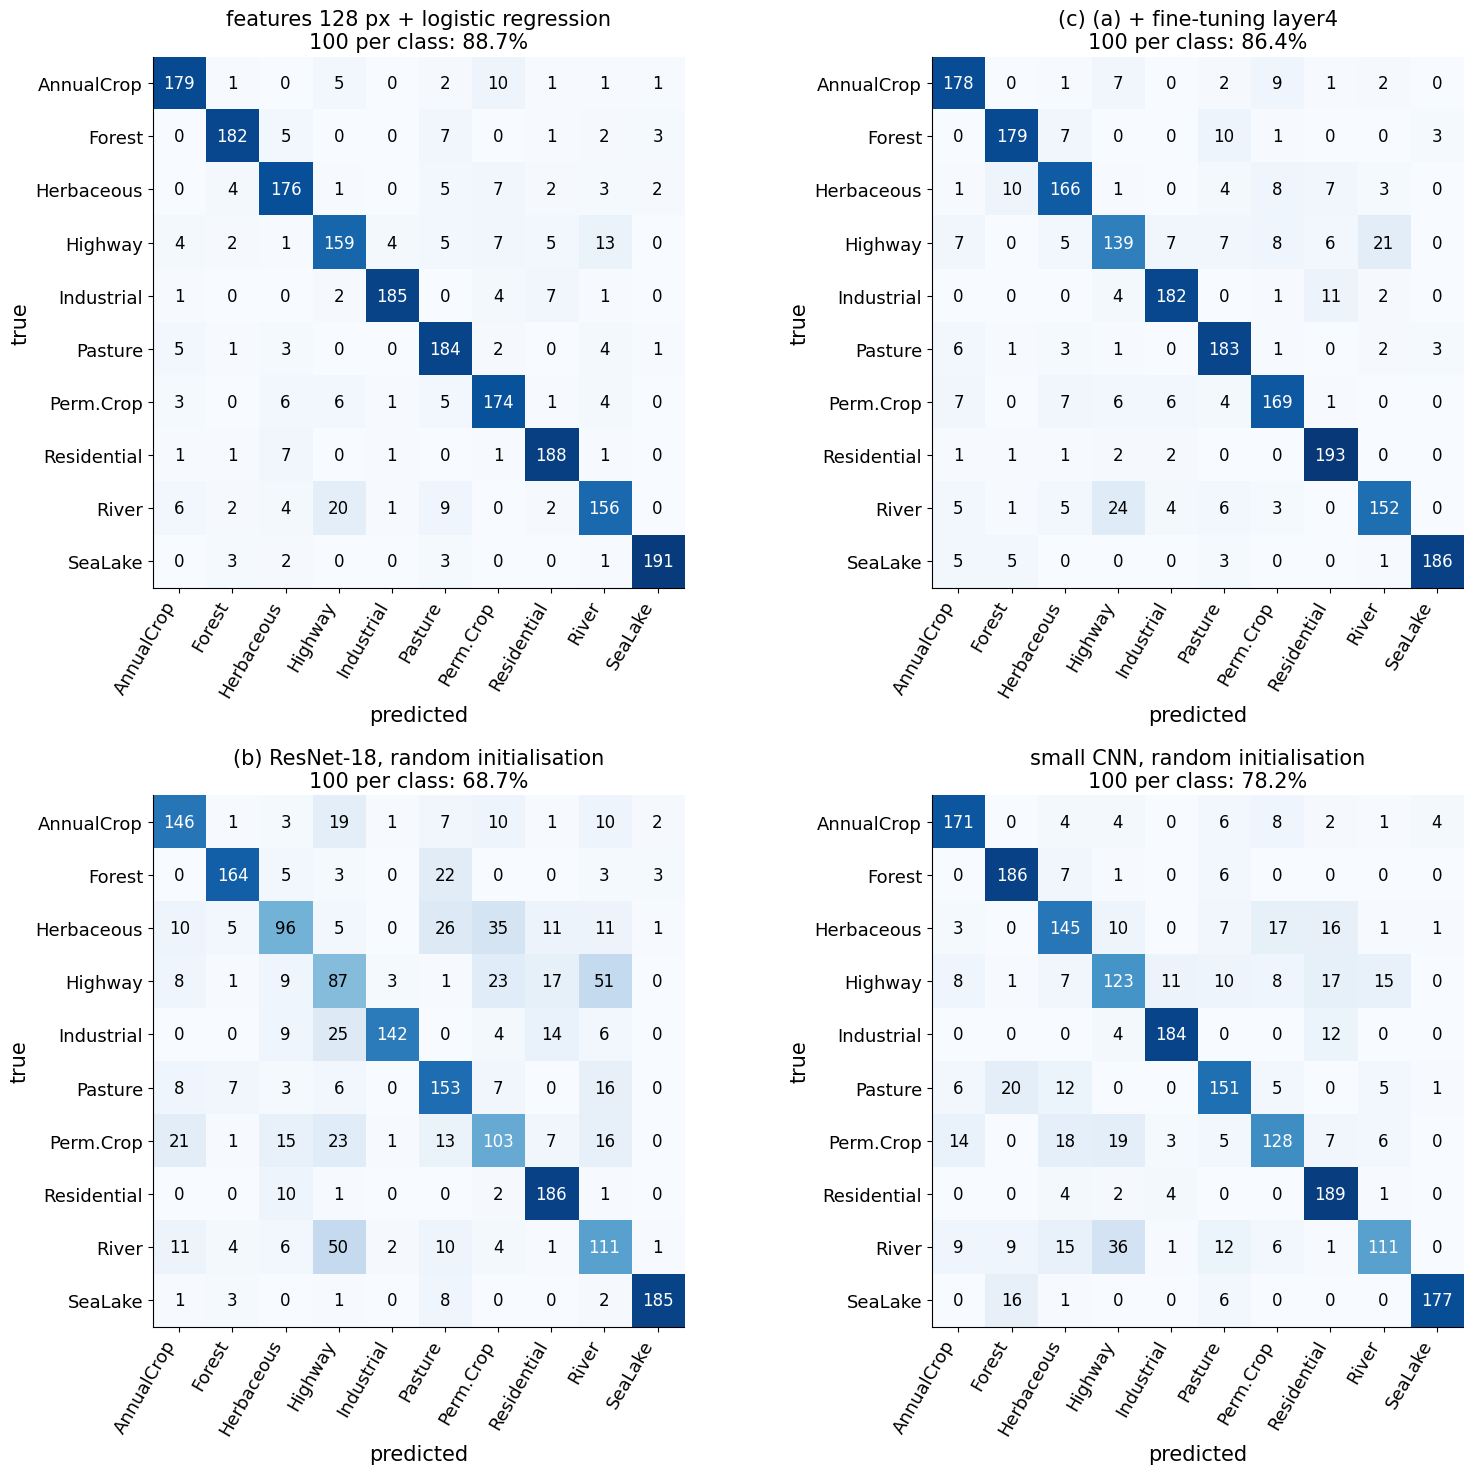

saved results/Lab_014b_eurosat_layer4_100_per_class.msgpack


saved results/Lab_014b_eurosat_resnet_random_100_per_class.msgpack
saved results/Lab_014b_eurosat_small_cnn_100_per_class.msgpack
saved results/Lab_014b_eurosat_logreg128_100_per_class.npz


In [50]:
EU_SHORT = [{"HerbaceousVegetation": "Herbaceous", "PermanentCrop": "Perm.Crop"}.get(c, c) for c in EURO_CLASSES]
preds = {"logreg128": LR_EU[("128", 100)].predict(Fe_te128),
         "layer4": predict(MODELS_EU[("layer4", 100)], H3e_te, fn=top_logits).argmax(1),
         "resnet_random": predict(MODELS_EU[("resnet_random", 100)], Xe_te).argmax(1),
         "small_cnn": predict(MODELS_EU[("small_cnn", 100)], X32_te).argmax(1)}
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for ax, (m, pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(ye_te, pred, n=10)
    plot_confusion(ax, cm, EU_SHORT, f"{LABELS_EU[m]}\n100 per class: {100 * (pred == ye_te).mean():.1f}%")
    off = cm - np.diag(np.diag(cm)); a, b = np.unravel_index(off.argmax(), off.shape)
    print(f"{LABELS_EU[m]:40s} most frequent error {EURO_CLASSES[a]} -> {EURO_CLASSES[b]} ({off[a, b]} of 200)")
plt.tight_layout(); plt.show()
for m in ["layer4", "resnet_random", "small_cnn"]:
    print("saved", save(MODELS_EU[(m, 100)], os.path.join(RESULTS, f"Lab_014b_eurosat_{m}_100_per_class.msgpack")))
clf = LR_EU[("128", 100)]; path = os.path.join(RESULTS, "Lab_014b_eurosat_logreg128_100_per_class.npz")
np.savez(path, coef=clf[-1].coef_, intercept=clf[-1].intercept_, mean=clf[0].mean_, scale=clf[0].scale_); print("saved", path)

The remaining errors of the pretrained models are between classes that genuinely look alike from orbit: rivers predicted as highways (20 and 24 of 200 for logistic regression and fine-tuning), both long bands crossing the patch. The two networks trained from random initialisation make the same confusion in either direction, highways predicted as rivers (51 of 200) for the ResNet-18 and rivers as highways (36 of 200) for the small CNN.

## 5. Cheat sheet for PyTorch and JAX

| task | PyTorch | JAX with Flax (`flax.nnx`) and Optax |
|---|---|---|
| split body and head | modules `model.body`, `model.head` (or `model.fc` in torchvision) | attributes `model.body`, `model.head`, `model.fc` of the `nnx.Module` |
| replace a head | `model.fc = nn.Linear(512, 8)` | `model.fc = nnx.Linear(512, 8, rngs=nnx.Rngs(0))` |
| freeze parameters | `for p in model.body.parameters(): p.requires_grad = False` | no flag: select the trainable part with a filter, e.g. `nnx.All(nnx.Param, nnx.PathContains("head"))` |
| gradients of the trainable part only | automatic for parameters with `requires_grad=True` | `nnx.value_and_grad(loss, argnums=nnx.DiffState(0, filter))` |
| optimiser on the trainable part only | `torch.optim.Adam(model.head.parameters(), lr)` | `nnx.Optimizer(model, optax.adam(lr), wrt=filter)` |
| discard updates of a group | not needed (no gradient, no update) | `optax.multi_transform({"train": optax.adam(lr), "freeze": optax.set_to_zero()}, labels)` |
| different learning rates | parameter groups: `Adam([{"params": body, "lr": 1e-4}, {"params": head, "lr": 1e-3}])` | `optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(1e-3)}, labels)` |
| keep batch-norm statistics fixed | `model.body.eval()` after `model.train()` | `model.body.eval()` after `model.train()` |
| check that frozen weights did not move | compare `state_dict()` before and after with `torch.equal` | compare `nnx.state(model.body, (nnx.Param, nnx.BatchStat))` with `np.array_equal` |
| download pretrained weights | `torchvision.models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)` | no model zoo in Flax: write the architecture in `nnx`, convert the torchvision weights |
| convert a convolution kernel | `conv.weight`: $(C_{\text{out}}, C_{\text{in}}, k_h, k_w)$ | `conv.kernel`: $(k_h, k_w, C_{\text{in}}, C_{\text{out}})$ = `w.transpose(2, 3, 1, 0)` |
| convert a dense layer | `fc.weight`: $(n_{\text{out}}, n_{\text{in}})$ | `fc.kernel`: $(n_{\text{in}}, n_{\text{out}})$ = `w.T` |
| convert batch normalisation | `weight`, `bias`, `running_mean`, `running_var` | `scale`, `bias`, `mean`, `var` (Flax momentum 0.9 corresponds to PyTorch momentum 0.1; epsilon $10^{-5}$ in both) |
| preprocessing of pretrained weights | `weights.transforms()`: mean and standard deviation per channel | the same numbers, applied to arrays $(N, H, W, C)$ |
| feature extraction | `with torch.no_grad(): model.eval(); h = body(x)` | `model.eval(); h = nnx.jit(lambda m, x: m.features(x))(model, x)` |
| linear head on stored features | `sklearn.linear_model.LogisticRegression().fit(h, y)` | the same, on `np.asarray(h)` |
| save weights | `torch.save(model.state_dict(), path)` | `flax.serialization.msgpack_serialize(nnx.to_pure_dict(nnx.state(model, (nnx.Param, nnx.BatchStat))))` |

In [51]:
print(f"total run time of the notebook: {(time.time() - T_START) / 60:.1f} min")

total run time of the notebook: 254.4 min
